# 第6章实验｜泛化、诊断与模型选择

本Notebook配合本讲课件，按代码依赖组织实验，不要求与课件逐页同序。

**主线**：Diabetes真实数据区分训练误差与留出估计 → digits固定留出与五折／LOO → Bootstrap观察训练波动 → 学习曲线与验证曲线诊断 → 搜索超参数、重采样和图像增强 → 比较复杂度、正则化与错误模式。分组和时间划分用于说明：评价数据应对应未来部署对象。

**目标**：评价泛化表现，利用诊断改进模型，再检查选择是否可靠。训练数据拟合模型与预处理；开发验证用于比较方案，选中的最高分不是独立测试成绩。digits的360条预留数据不参与本Notebook选择。

**选读与附录**：特征选择泄漏、少样本协议、Bootstrap均值、独立重复模拟及四种搜索机制。Elastic Net与早停补充对应课件的概念说明，不要求安装深度学习框架或训练元学习模型。末尾的维护用导出只保存本次计算结果。

**来源**：采用scikit-learn官方digits、Diabetes及交叉验证API；上游代码来源为The scikit-learn developers，BSD-3-Clause。其余数据来源与许可在各实验中说明。[交叉验证](https://scikit-learn.org/stable/modules/cross_validation.html) · [调参](https://scikit-learn.org/stable/modules/grid_search.html) · [常见泄漏](https://scikit-learn.org/stable/common_pitfalls.html)。

**阅读约定**：真实数据实验与教学模拟分别标注；模拟中已知真函数，不代表真实任务也能直接测得总体偏差。Bootstrap条件于现有数据的波动，也不能代替对未知总体风险的独立评价。

In [1]:
# 显示辅助：放大 Notebook 正文、表格和 print 输出；运行本格即可应用。
from IPython.display import HTML, display
display(HTML("""<style id="course-notebook-readability">
.jp-Notebook, .jp-RenderedHTMLCommon, .jp-OutputArea-output { font-size: 20px !important; }
.jp-RenderedHTMLCommon table { font-size: 20px !important; }
.jp-OutputArea-output pre { font-size: 20px !important; }
</style>"""))


## 真实数据：风险图应该怎样读？

<!-- [ref:l6-risk-realdata] -->

**来源**：使用 [scikit-learn 官方 Diabetes 数据](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset)，通过 `load_diabetes(scaled=False)` 读取 的442条糖尿病患者记录，只取原始 BMI 这一列，目标是数据集定义的一年后疾病进展指标。这里的“风险”指平方损失的平均，不是患者个体的临床风险。

我们固定 `seed=42`，随机取20条训练、422条留出；只比较一个预先固定的1近邻回归模型。先看训练样本上的经验风险，再看未参与拟合的留出样本：总体风险未知，留出平均损失也只是一次估计。少数据＋单特征只服务于“训练分数为何会过于乐观”的教学问题，不作临床结论。

In [2]:
# 自含导入与数据加载；变量使用 diabetes_/risk_ 前缀，不影响后面的 digits 主线。
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

diabetes_data = load_diabetes(scaled=False)
diabetes_bmi = diabetes_data.data[:, [2]]
diabetes_target = diabetes_data.target
risk_seed = 42
risk_train_idx, risk_heldout_idx = train_test_split(
    np.arange(len(diabetes_target)), train_size=20, random_state=risk_seed
)
print("原始数据:", diabetes_bmi.shape, "| 训练/留出:", len(risk_train_idx), len(risk_heldout_idx))


原始数据: (442, 1) | 训练/留出: 20 422


### 先有基线，再拟合一个固定模型

`DummyRegressor(strategy="mean")` 总是预测训练集均值，是不使用 BMI 的基线。随后固定 `KNeighborsRegressor(n_neighbors=1)`：每个输入只找训练集中 BMI 最近的一条记录。这里没有搜索参数，也没有用留出数据选模型。

In [3]:
risk_dummy = DummyRegressor(strategy="mean").fit(
    diabetes_bmi[risk_train_idx], diabetes_target[risk_train_idx]
)
risk_model = KNeighborsRegressor(n_neighbors=1).fit(
    diabetes_bmi[risk_train_idx], diabetes_target[risk_train_idx]
)
risk_dummy_pred = risk_dummy.predict(diabetes_bmi[risk_heldout_idx])
risk_pred = risk_model.predict(diabetes_bmi)
risk_loss = (diabetes_target - risk_pred) ** 2
print("Dummy 留出 MSE:", round(float(np.mean((diabetes_target[risk_heldout_idx] - risk_dummy_pred) ** 2)), 4))
print("1近邻训练/留出 MSE:", round(float(risk_loss[risk_train_idx].mean()), 2), "/", round(float(risk_loss[risk_heldout_idx].mean()), 4))
print("训练 BMI 不同取值:", len(np.unique(diabetes_bmi[risk_train_idx])))


Dummy 留出 MSE: 5886.5077
1近邻训练/留出 MSE: 90.65 / 8207.3768
训练 BMI 不同取值: 18


In [4]:
risk_train_mse = float(risk_loss[risk_train_idx].mean())
risk_heldout_mse = float(risk_loss[risk_heldout_idx].mean())
risk_show_idx = np.r_[risk_train_idx[:3], risk_heldout_idx[:3]]
risk_table = pd.DataFrame({
    "样本": risk_show_idx, "划分": np.where(np.isin(risk_show_idx, risk_train_idx), "训练", "留出"),
    "BMI": diabetes_bmi[risk_show_idx, 0], "真实值": diabetes_target[risk_show_idx],
    "预测值": risk_pred[risk_show_idx], "平方损失": risk_loss[risk_show_idx],
})
display(risk_table.round({"BMI": 1, "预测值": 1, "平方损失": 1}))


,样本,划分,BMI,真实值,预测值,平方损失
0,308,训练,22.1,114.0,114.0,0.0
1,149,训练,25.9,126.0,126.0,0.0
2,130,训练,35.3,274.0,274.0,0.0
3,287,留出,25.8,219.0,134.0,7225.0
4,211,留出,29.8,70.0,270.0,40000.0
5,72,留出,26.0,202.0,88.0,12996.0


训练样本的平方损失均值是 **90.65**，但这不是未来患者的风险：1近邻模型已经看过这20条记录，而且训练 BMI 有重复值，所以训练误差仍然非零。422条留出记录上的平方损失均值是 **8207.3768**，它只是在这个固定划分下对未知总体风险的估计。目标均值为153.45；Dummy基线的训练 MSE 是6883.4475、留出 MSE 是5886.5077，1近邻虽训练误差更低，留出误差却更高。

Matplotlib is building the font cache; this may take a moment.


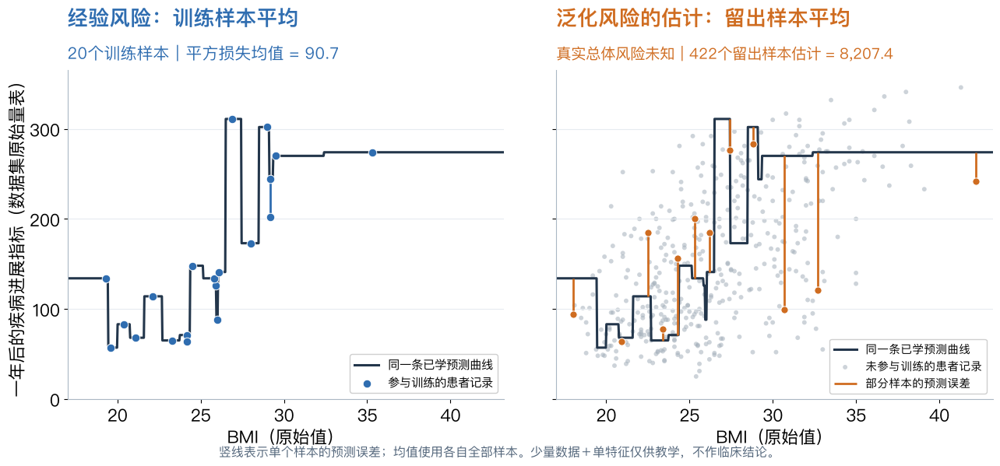

/Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-risk-realdata.png


In [5]:
# 绘图 helper 只负责画图；训练、预测和损失都在上面的 Notebook 单元中。
risk_project_root = next(parent for parent in [Path.cwd(), *Path.cwd().parents]
                         if (parent / "lessons").is_dir())
risk_helper_dir = risk_project_root / "lessons/06-model-selection/notebook/helpers"
if str(risk_helper_dir) not in sys.path:
    sys.path.insert(0, str(risk_helper_dir))
from risk_realdata_plots import plot_diabetes_risk_realdata

risk_assets_dir = risk_project_root / "lessons/06-model-selection/assets"
risk_assets_dir.mkdir(exist_ok=True)
risk_figure_path = risk_assets_dir / "l6-risk-realdata.png"
plot_diabetes_risk_realdata(
    diabetes_bmi[risk_train_idx], diabetes_target[risk_train_idx],
    diabetes_bmi[risk_heldout_idx], diabetes_target[risk_heldout_idx],
    risk_model, risk_pred[risk_train_idx], risk_pred[risk_heldout_idx],
    risk_train_mse, risk_heldout_mse, risk_figure_path, compact=True,
)
import matplotlib.pyplot as plt
plt.show()
print(risk_figure_path)


### 读图

<!-- [ref:l6-risk-realdata-figure] -->

两幅图使用同一条已学预测曲线和同一坐标：左图只平均20条训练记录，右图平均全部422条留出记录；竖线是单个样本的预测误差。右图的平均损失用于估计泛化风险，但真实总体风险仍然未知。

## 用 Ridge 重画同一风险问题

<!-- [ref:l6-risk-ridge] -->

在同一划分上，再拟合一个五次多项式 Ridge：比较同一个模型在训练样本与留出样本上的损失。沿用 `seed=42`、20/422 划分和单一 BMI 特征；次数与正则强度预先固定，不用留出成绩选参。

In [6]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 训练显式写在 Notebook：预处理只在这20条训练记录上拟合。
ridge_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=5, include_bias=False),
    StandardScaler(),
    Ridge(alpha=1),
)
ridge_model.fit(diabetes_bmi[risk_train_idx], diabetes_target[risk_train_idx])
ridge_pred = ridge_model.predict(diabetes_bmi)
ridge_loss = (diabetes_target - ridge_pred) ** 2
ridge_train_mse = float(ridge_loss[risk_train_idx].mean())
ridge_heldout_mse = float(ridge_loss[risk_heldout_idx].mean())
print("Ridge 训练/留出 MSE:", ridge_train_mse, "/", ridge_heldout_mse)


Ridge 训练/留出 MSE: 2073.1955934059893 / 18282.231325870976


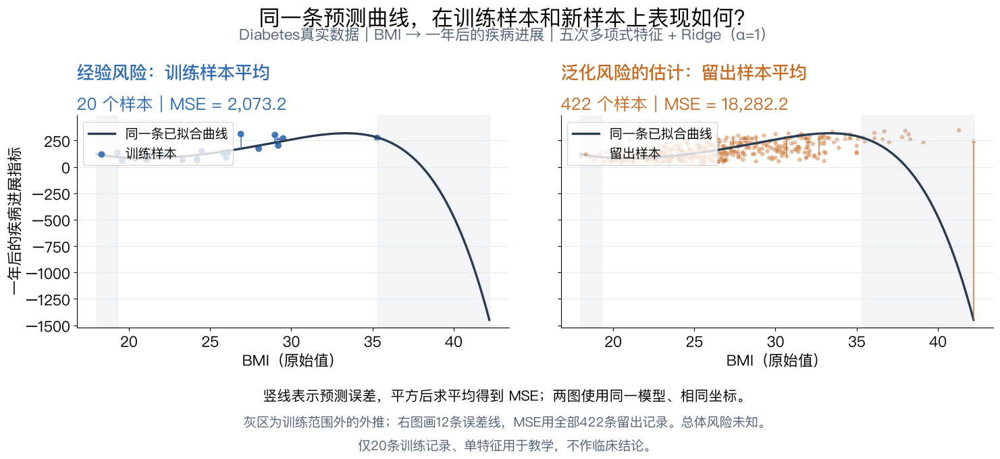

/Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-risk-ridge.png


In [7]:
# helper 只接收数据和已拟合模型；不在 helper 中训练。
from risk_ridge_plots import plot_diabetes_risk_ridge

ridge_figure_path = risk_assets_dir / "l6-risk-ridge.png"
plot_diabetes_risk_ridge(
    diabetes_bmi, diabetes_target, risk_train_idx, risk_heldout_idx,
    ridge_model, ridge_figure_path,
)
plt.show()
print(ridge_figure_path)


### 读 Ridge 图

<!-- [ref:l6-risk-ridge-figure] -->

Ridge 的训练 MSE 为 **2073.2**，留出 MSE 为 **18282.2**；这次拟合在训练记录上的损失更小。灰色区域超出训练 BMI 范围，右端出现明显外推失真，不能把误差差异全部归因于过拟合。留出均值只是泛化风险的估计，总体风险仍未知。这里的20条训练记录和单特征设置只用于教学，不能据此作临床判断。

## 先做一次固定留出

**问题**：同一批 digits，只改变正则化强度 `C`，训练分数和验证分数会怎样变化？

`C`是Logistic回归中正则化强度的倒数参数：越小惩罚越强，越大惩罚越弱；权重由训练学出，C由验证比较选择。详细惩罚形式见后面的正则化实验。

这里固定 `random_state=42`：先从 1797 条样本取出 360 条预留数据，剩下 1437 条开发数据；再把开发数据分成训练 1077 条和验证 360 条。这个表适合开场比较候选，不承担最终性能报告。

In [8]:
# 记录环境与可复现参数；本单元不训练模型。
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
CANDIDATES_OPENING = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]
CANDIDATES_CV = list(CANDIDATES_OPENING)  # 九档C共用一次五折结果
digits = load_digits()
X, y = digits.data, digits.target
project_root = next(parent for parent in [Path.cwd(), *Path.cwd().parents]
                    if (parent / "lessons").is_dir())
assets_dir = project_root / "lessons/06-model-selection/assets"
assets_dir.mkdir(exist_ok=True)
helper_dir = project_root / "lessons/06-model-selection/notebook/helpers"
if str(helper_dir) not in sys.path:
    sys.path.insert(0, str(helper_dir))
from selection_plots import (plot_opening, plot_learning, plot_selection,
                             plot_leakage, plot_complexity, plot_decomposition)
from course_plot_style import course_font_settings
plt.rcParams.update({**course_font_settings(), "figure.dpi": 140})
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__)
print("digits:", X.shape, "| seed:", SEED)

Python 3.14.6 | scikit-learn 1.9.0
digits: (1797, 64) | seed: 42


### 固定两次划分

第一次留出的 360 条只叫“预留数据”，本节不触碰它。第二次划分只在 1437 条开发数据中进行，因此训练、验证、预留三个集合大小固定为 1077、360、360。

In [9]:
# [ref:l6-opening]
X_develop, X_reserved, y_develop, y_reserved = train_test_split(
    X, y, test_size=360, stratify=y, random_state=SEED
)
X_open_train, X_open_valid, y_open_train, y_open_valid = train_test_split(
    X_develop, y_develop, test_size=360, stratify=y_develop, random_state=SEED
)
print({"训练": len(y_open_train), "验证": len(y_open_valid), "预留": len(y_reserved)})

{'训练': 1077, '验证': 360, '预留': 360}


### 候选 `C` 与 Dummy 基线

`C` 越大，正则化越弱。本节从0.0001到10000按10倍递增，共比较9个候选；所有候选使用相同划分和 `StandardScaler`→`LogisticRegression` 流程。`DummyClassifier` 只学习训练集中的多数类，提供基线。这里的范围探索与后面预先固定4个C的五折选参实验分开记录。

In [10]:
opening_rows = []
print("候选 C:", CANDIDATES_OPENING)
opening_models = {}  # 保存各C已拟合的模型，供后续读取权重。


候选 C: [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]


In [11]:
for C in CANDIDATES_OPENING:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("logistic", LogisticRegression(C=C, max_iter=1000, random_state=SEED)),
    ])
    model.fit(X_open_train, y_open_train)
    opening_models[C] = model
    opening_rows.append({"C": C,
        "训练准确率": accuracy_score(y_open_train, model.predict(X_open_train)),
        "验证准确率": accuracy_score(y_open_valid, model.predict(X_open_valid))})

,C,训练准确率,验证准确率
0,0.0001,0.8459,0.8222
1,0.001,0.9136,0.9000
2,0.01,0.9526,0.9500
3,0.1,0.9916,0.9694
4,1,0.9991,0.9722
5,10,1.0000,0.9694
6,100,1.0000,0.9583
7,1000,1.0000,0.9611
8,10000,1.0000,0.9639
9,Dummy,0.1012,0.1028


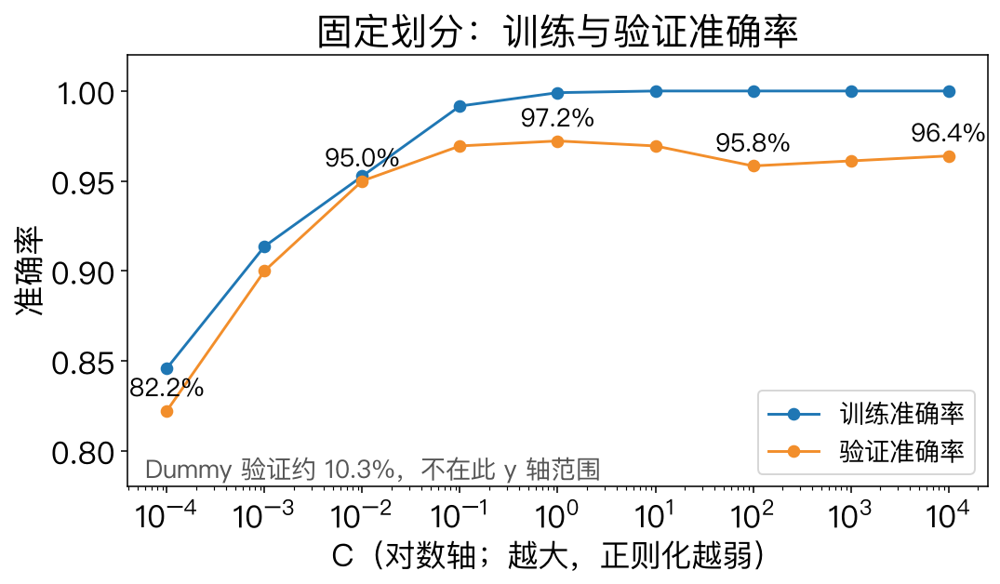

In [12]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_open_train, y_open_train)
opening_rows.append({"C": "Dummy",
    "训练准确率": accuracy_score(y_open_train, dummy.predict(X_open_train)),
    "验证准确率": accuracy_score(y_open_valid, dummy.predict(X_open_valid))})
opening_table = pd.DataFrame(opening_rows)
display(opening_table.round(4))
plot_opening(opening_table, assets_dir)
plt.show()

### 同一批训练模型：把各个C的权重排成竖带

<!-- [ref:l6-opening-weights] -->

每个C的多分类Logistic回归都有10×64个权重（`coef_`形状为`(10, 64)`），另有10个截距。每列对应一个C，纵向先按类别0—9，再按各类64个像素特征的原顺序排列。它是参数排列，不是8×8图像。

这些系数作用于训练侧标准化后的输入；各C使用相同训练划分和标准化统计量，共用对称对数色标（零附近线性，其余对数压缩），让小C下的非零权重也能显色，不做逐列归一化。颜色深浅不能按线性比例比较数值大小。白色是接近0，不能据此认定系数恰为0。下面只读取已训练模型，不再拟合。


In [13]:
# 读取同一批模型的系数；不含10个截距。
opening_weights = np.stack([opening_models[c].named_steps["logistic"].coef_
                            for c in CANDIDATES_OPENING])
assert opening_weights.shape == (9, 10, 64)  # 九个C，各有10类×64个系数。
opening_classes = opening_models[CANDIDATES_OPENING[0]].named_steps["logistic"].classes_
print("每个C的权重维度：", opening_weights.shape[1:])
print("类别顺序：", opening_classes)
# 核对各C的预处理相同，才能直接比较标准化坐标中的权重。
assert all(np.allclose(model.named_steps["scale"].scale_,
                       opening_models[CANDIDATES_OPENING[0]].named_steps["scale"].scale_)
           for model in opening_models.values())


每个C的权重维度： (10, 64)
类别顺序： [0 1 2 3 4 5 6 7 8 9]


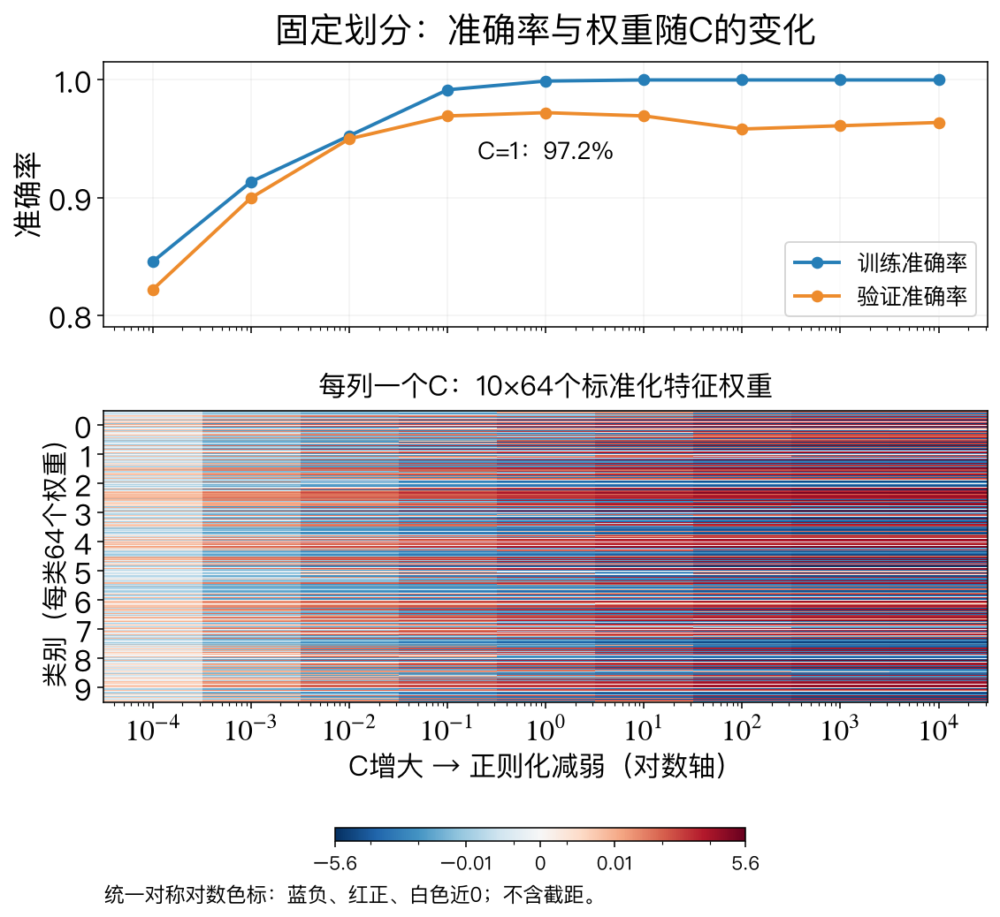

165444

In [14]:
from opening_weight_plots import plot_opening_weights

plot_opening_weights(opening_table, opening_weights, assets_dir)
plt.show()
# 保存真实系数，方便复核热力图与类别顺序。
(assets_dir / "l6-opening-weights-data.json").write_text(json.dumps({
    "C": CANDIDATES_OPENING, "classes": opening_classes.tolist(),
    "shape": list(opening_weights.shape), "weights": opening_weights.tolist(),
    "coordinate": "training-standardized features; class-major order; intercept excluded"},
    ensure_ascii=False, indent=2), encoding="utf-8")


**读图**：本例C增大时，系数整体更明显，表示惩罚减弱；但验证准确率在C=1附近已达到较高水平。更大的权重和更高的训练准确率，并不保证更好的验证表现。不能据图断言每个权重都随C单调增大。


**先停一下**：验证准确率最高的一行能否直接当作模型在未来数据上的准确率？不能。它只回答了这一次固定划分上的比较；接下来把 1437 条开发数据交给五折交叉验证。

In [15]:
# [ref:l6-optimization]
import warnings
from sklearn.exceptions import ConvergenceWarning

opening_fixed_model = Pipeline([("scale", StandardScaler()),
    ("logistic", LogisticRegression(C=1, max_iter=1000, random_state=SEED))])
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    opening_fixed_model.fit(X_open_train, y_open_train)
optimization_summary = {"pipeline": "StandardScaler → LogisticRegression(C=1)",
    "n_iter": opening_fixed_model.named_steps["logistic"].n_iter_.tolist(),
    "convergence_warnings": sum(isinstance(w.message, ConvergenceWarning) for w in fit_warnings)}
print("开场固定模型:", optimization_summary)

开场固定模型: {'pipeline': 'StandardScaler → LogisticRegression(C=1)', 'n_iter': [31], 'convergence_warnings': 0}


,索引,真实,预测
0,28,9,8
1,34,4,7
2,66,8,4
3,101,9,1
4,145,9,1
5,148,5,9


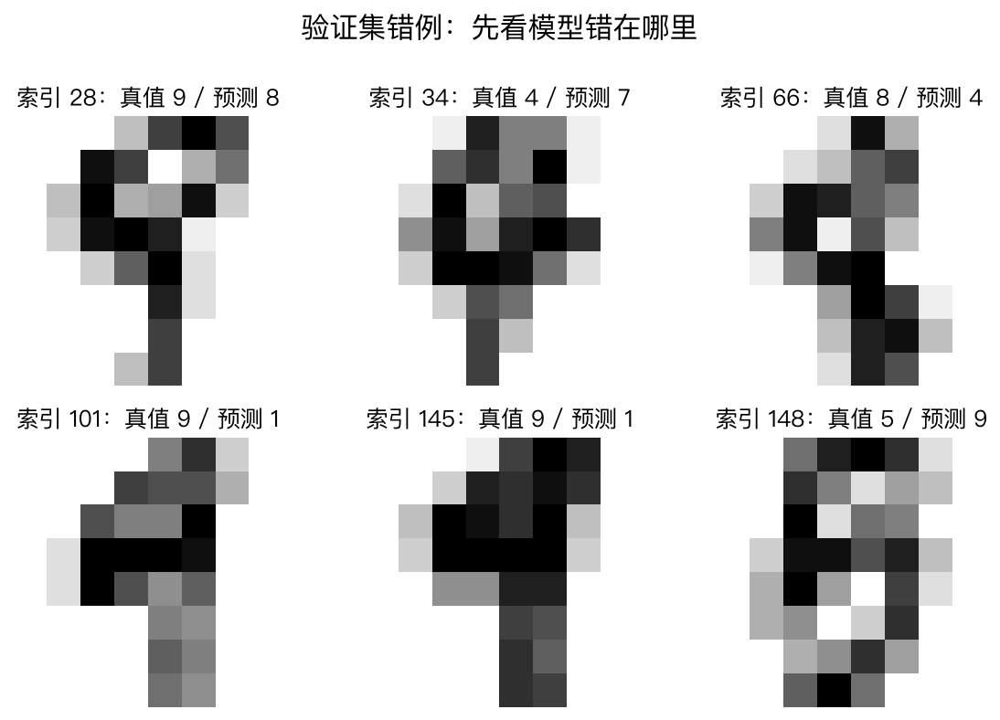

In [16]:
# [ref:l6-errors]
from generalization_plots import error_examples_plot

opening_valid_pred = opening_fixed_model.predict(X_open_valid)
error_indices = np.flatnonzero(opening_valid_pred != y_open_valid)
error_table = pd.DataFrame({"索引": error_indices, "真实": y_open_valid[error_indices],
                            "预测": opening_valid_pred[error_indices]})
error_examples = error_table.head(6)
display(error_examples)
error_examples_plot(X_open_valid[error_examples["索引"]].reshape(-1, 8, 8), error_examples, assets_dir); plt.show()
error_summary = {"validation_errors": int(len(error_table)), "shown": int(len(error_examples)), "uses_reserved": False}

### 错误分析｜先汇总，再提出一个可检验的假设

回到 **8×8 digits**，与后面的28×28 MNIST增强实验区分。沿用开场1077条训练、360条开发验证和固定的Logistic回归，不使用预留数据。

先对**全部验证样本**按真实类别统计错误率，分母是该类实际人数；再汇总真实类别→预测类别的混淆次数。不能仅凭前六张错图推断主要问题。

In [17]:
# [ref:l6-error-groups]
error_group_table = pd.DataFrame({"真实类别": y_open_valid,
                                  "错误": opening_valid_pred != y_open_valid})
error_group_table = error_group_table.groupby("真实类别")["错误"].agg(样本数="size", 错误数="sum")
error_group_table["错误率"] = error_group_table["错误数"] / error_group_table["样本数"]
display(error_group_table)
error_pair_table = error_table.groupby(["真实", "预测"]).size().rename("次数").sort_values(ascending=False)
display(error_pair_table)


,样本数,错误数,错误率
真实类别,,,
0,36,0,0.000000
1,37,1,0.027027
2,35,1,0.028571
3,37,0,0.000000
4,36,1,0.027778
5,36,1,0.027778
6,36,2,0.055556
7,36,0,0.000000
8,35,1,0.028571


真实  预测
9   1     2
1   9     1
2   1     1
4   7     1
5   9     1
6   1     1
    5     1
8   4     1
9   8     1
Name: 次数, dtype: int64

### 对照｜仅替换分类器，是否改变错误模式？

**开发假设**：基线对部分笔迹的区分，是否能通过局部相似样本的比较改善？这还不是对错误原因的证明。

保留相同数据、像素特征和StandardScaler，只把Logistic回归换成4近邻、距离加权规则。不同时加数据或做增强，不搜索k，也不查看预留标签。用这个固定候选检验假设。

In [18]:
# [ref:l6-error-candidate]
from sklearn.neighbors import KNeighborsClassifier
error_candidate = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=4, weights="distance"))])
error_candidate.fit(X_open_train, y_open_train)
error_candidate_pred = error_candidate.predict(X_open_valid)
error_old_wrong = opening_valid_pred != y_open_valid
error_new_wrong = error_candidate_pred != y_open_valid


In [19]:
# [ref:l6-error-comparison]
error_comparison = pd.DataFrame({
    "分类器": ["Logistic回归", "4近邻（距离加权）"],
    "全部错误数": [int(error_old_wrong.sum()), int(error_new_wrong.sum())],
    "数字9错误数": [int((error_old_wrong & (y_open_valid == 9)).sum()),
                      int((error_new_wrong & (y_open_valid == 9)).sum())]})
error_comparison["验证准确率"] = 1 - error_comparison["全部错误数"] / len(y_open_valid)
display(error_comparison)
error_fixed = int((error_old_wrong & ~error_new_wrong).sum())
error_added = int((~error_old_wrong & error_new_wrong).sum())
error_retained = int((error_old_wrong & error_new_wrong).sum())
print(f"修正旧错 {error_fixed}；新增错误 {error_added}；仍然出错 {error_retained}")
assert error_old_wrong.sum() - error_new_wrong.sum() == error_fixed - error_added


,分类器,全部错误数,数字9错误数,验证准确率
0,Logistic回归,10,3,0.972222
1,4近邻（距离加权）,9,1,0.975000


修正旧错 7；新增错误 6；仍然出错 3


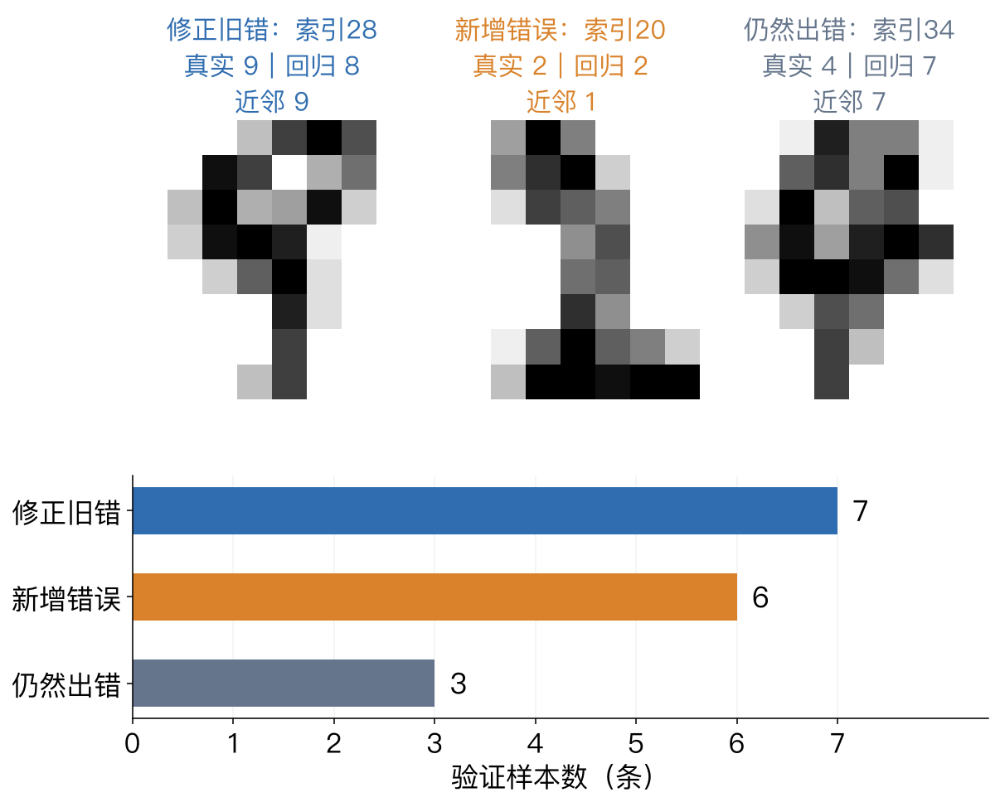

209

In [20]:
# [ref:l6-error-analysis]
from error_analysis_plots import plot_error_changes
plot_error_changes(X_open_valid, y_open_valid, opening_valid_pred, error_candidate_pred, assets_dir)
plt.show()
error_analysis_summary = {"train_n": len(y_open_train), "valid_n": len(y_open_valid),
    "before_errors": int(error_old_wrong.sum()), "after_errors": int(error_new_wrong.sum()),
    "nine_n": int((y_open_valid == 9).sum()),
    "nine_before": int((error_old_wrong & (y_open_valid == 9)).sum()),
    "nine_after": int((error_new_wrong & (y_open_valid == 9)).sum()),
    "fixed": error_fixed, "added": error_added, "retained": error_retained,
    "uses_reserved": False}
(assets_dir / "l6-error-analysis-summary.json").write_text(json.dumps(error_analysis_summary, ensure_ascii=False, indent=2))


**读结果**：同时看修正了多少旧错、新增了多少错误，以及总体和分组指标。局部改善不等于整体明显改善；一种模型的错误也可能被另一种错误替代。

**评价边界**：这仍是已参与诊断和候选设计的开发验证结果，不能证明错误一定由线性边界造成，也不能凭一次划分的一条样本之差宣布模型稳定更优。下一步在开发数据内用固定CV比较，最后再做独立评价。

参考：[sklearn手写数字分类与混淆矩阵](https://scikit-learn.org/stable/auto_examples/classification/plot_digits_classification.html)、[避免在测试集选择方案](https://scikit-learn.org/stable/common_pitfalls.html)。

## 手工走一折，再自动五折

先把“训练折 fit、验证折 predict、最后评分”写出来。自动 API 只是把同一过程重复；它不会改变验证对象。

In [21]:
# [ref:l6-cv-manual]
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
manual_train_idx, manual_valid_idx = next(cv5.split(X_develop, y_develop))
manual_model = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(C=1, max_iter=1000, random_state=SEED)),
])
manual_model.fit(X_develop[manual_train_idx], y_develop[manual_train_idx])
manual_score = accuracy_score(
    y_develop[manual_valid_idx], manual_model.predict(X_develop[manual_valid_idx])
)
print("训练折/验证折:", len(manual_train_idx), len(manual_valid_idx), "| 验证准确率:", round(manual_score, 4))

训练折/验证折: 1149 288 | 验证准确率: 0.9583


### 五折先固定 `C=1`

这一步只展示一个预先固定的模型。每一折重新拟合缩放器与分类器，避免验证折参与预处理。

In [22]:
# [ref:l6-cv-scores]
fixed_cv_scores = cross_val_score(
    manual_model, X_develop, y_develop, cv=cv5, scoring="accuracy", n_jobs=1
)
print("五折准确率:", np.round(fixed_cv_scores, 4))
print("均值 ± 标准差:", round(fixed_cv_scores.mean(), 4), "±", round(fixed_cv_scores.std(), 4))

五折准确率: [0.9583 0.9688 0.9721 0.9617 0.9791]
均值 ± 标准差: 0.968 ± 0.0074


## 留一法实测：与五折比较

使用相同的1437条开发数据、相同的标准化＋Logistic回归（`C=1`），不选择新的超参数。最终360条预留数据仍不参与。

五折每轮留出一组；LOO每轮只留出一个样本，因此需要拟合1437次。两者都在**各自训练折内重新拟合缩放器**。LOO不是只训练一个模型，再轮流预测1437个样本。

本实验串行运行，并将数值计算线程限制为1以便比较耗时；耗时仍受机器与负载影响。

In [23]:
# [ref:l6-loo]
from time import perf_counter
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from threadpoolctl import threadpool_limits

# 每种协议都生成1437个折外预测；顺序与原样本一致。
protocols = [("五折", cv5), ("LOO", LeaveOneOut())]
oof_predictions, protocol_elapsed = {}, {}
with threadpool_limits(limits=1):
    for name, splitter in protocols:
        started = perf_counter()
        oof_predictions[name] = cross_val_predict(
            manual_model, X_develop, y_develop,
            cv=splitter, method="predict", n_jobs=1,
        )
        protocol_elapsed[name] = perf_counter() - started


### 汇总折外预测

先数每种协议答对多少条，再除以同一个总样本数。拟合次数由划分器给出；这里不再训练模型。

In [24]:
protocol_rows = []
for name, splitter in protocols:
    correct = int(np.count_nonzero(oof_predictions[name] == y_develop))
    protocol_rows.append({
        "方法": name,
        "每轮训练数": "1149或1150" if name == "五折" else "1436",
        "每轮验证数": "287或288" if name == "五折" else "1",
        "拟合次数": splitter.get_n_splits(X_develop, y_develop),
        "答对数": correct, "总数": len(y_develop),
        "折外总体准确率": correct / len(y_develop),
        "串行耗时（秒）": protocol_elapsed[name],
    })
protocol_comparison = pd.DataFrame(protocol_rows)
assert len(oof_predictions["LOO"]) == len(y_develop) == 1437
assert np.isclose(protocol_comparison.iloc[0]["折外总体准确率"],
                  fixed_cv_scores.mean(), atol=1 / len(y_develop))
display(protocol_comparison.round(4))


,方法,每轮训练数,每轮验证数,拟合次数,答对数,总数,折外总体准确率,串行耗时（秒）
0,五折,1149或1150,287或288,5,1391,1437,0.9680,0.0307
1,LOO,1436,1,1437,1397,1437,0.9722,9.5873


### 读结果：五折与LOO怎样选

表中的准确率均为“1437条折外预测的答对数÷1437”；前面五折的均值则是五个折分数等权平均，因折大小相差1，两者可能有极小差异。

LOO每个验证折只有一个样本，准确率非0即1；不比较这些单样本分数的标准差。LOO每次训练用的数据更多，但各轮训练集也高度重叠；一次实验分数略高，不能证明LOO始终更准、更稳定。这里还同时改变了每轮训练样本量。

**怎样选择**：常规选模可先用五折或十折；候选很多或训练较慢时，控制计算成本尤其重要。样本很少、单次训练便宜时，可考虑LOO，它让每轮训练量更接近最终的全量训练。

如果学习曲线还在明显上升，五折每次少用约20%的数据，可能把最终全量训练模型的误差估得偏高；LOO可减轻这种影响。但LOO不随机分折，不等于换一批数据时评价更稳定。不要因为本次LOO得分略高就更换协议。

**先看数据关系**：同一用户的多条记录应按组隔离；用过去预测未来时应按时间划分，不能直接套用普通随机五折或逐样本LOO。本讲“训练、验证、测试”页已提醒，“时间划分”页进一步介绍时间序列CV；第3讲p20则用十折CV选择多项式阶数。

绘图仅保留准确率比较，拟合次数与耗时可查上面的结果表。

参考：[Hastie：Cross-validation and the Bootstrap](https://web.stanford.edu/~hastie/MOOC-Slides/cv_boot.pdf)；[sklearn 留一法说明](https://scikit-learn.org/stable/modules/cross_validation.html#leave-one-out-loo)。

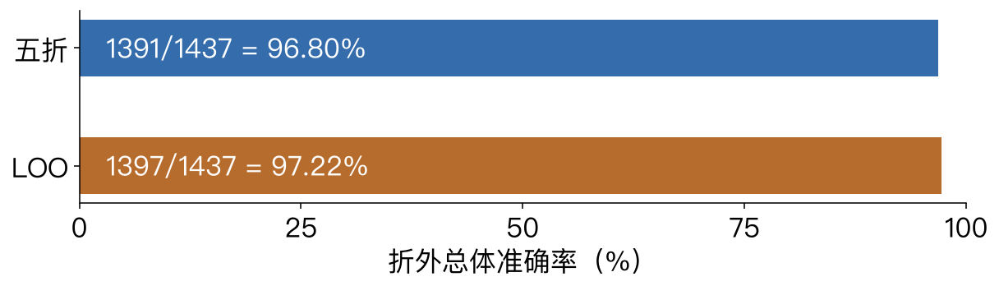

两种协议都错分的开发样本数： 37


In [25]:
# [ref:l6-loo-figure]
from selection_plots import plot_loo_comparison

plot_loo_comparison(protocol_comparison, assets_dir)
plt.show()
both_wrong = int(np.count_nonzero(
    (oof_predictions["五折"] != y_develop) &
    (oof_predictions["LOO"] != y_develop)
))
print("两种协议都错分的开发样本数：", both_wrong)


## Bootstrap：换一份训练集，模型会怎样？

划分与CV用于评价、选择模型；这里换一个问题：**如果重新取得一批训练样本，学到的模型与预测会变化多少？**

难以反复采集真实训练数据时，可用**自助法（Bootstrap）**：从原n条训练记录中有放回地抽n条，每份重新拟合一个模型，重复B次，观察同一输入的预测波动。它用训练经验分布近似抽样过程，不是创造新的独立数据。

本节沿用熟悉的Logistic回归。Iris两类共100条，只使用花瓣长度，固定70条训练、30条独立留出。C=1、划分种子42、B=200均预先固定，不靠留出结果调整。训练重抽与“固定模型、重抽评价集”是两个不同实验，本节只做前者。

**名字由来**：bootstrap原指靴子上的提环，借用“拽着自己的靴带把自己提起来”，比喻依靠已有样本。[名称来源](https://www.stat.umn.edu/geyer/3701/notes/bootstrap.html)。


In [26]:
# [ref:l6-bootstrap-data]
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

boot_iris = load_iris()
boot_keep = boot_iris.target > 0
boot_X = boot_iris.data[boot_keep, 2:3]  # 花瓣长度，单位cm
boot_y = (boot_iris.target[boot_keep] == 2).astype(int)
boot_train_idx, boot_eval_idx = train_test_split(
    np.arange(len(boot_y)), train_size=0.7, stratify=boot_y, random_state=SEED)
boot_X_train, boot_y_train = boot_X[boot_train_idx], boot_y[boot_train_idx]
boot_n, boot_B, boot_probe = len(boot_train_idx), 200, 4.8
print("训练/独立留出：", boot_n, len(boot_eval_idx), "；训练类人数：", np.bincount(boot_y_train))


训练/独立留出： 70 30 ；训练类人数： [35 35]


### 先固定训练规则，拟合原训练集模型

每个模型都采用`StandardScaler → LogisticRegression(C=1)`。标准化也属于拟合，每份重抽训练集都必须重新拟合完整Pipeline，不能只换最后一层权重。先用原70条训练记录拟合参考模型。


In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

boot_reference_model = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000))
boot_reference_model.fit(boot_X_train, boot_y_train)
boot_grid = np.linspace(2.8, 7.1, 180).reshape(-1, 1)
boot_reference_curve = boot_reference_model.predict_proba(boot_grid)[:, 1]
print("原训练集模型在4.8cm处的P(类别1)：", boot_reference_model.predict_proba([[boot_probe]])[0, 1])


原训练集模型在4.8cm处的P(类别1)： 0.42336524646241985


### 每次从原训练集中重抽，再重新训练

对**记录索引**有放回抽70次，X和y共用同一个索引；重复记录会影响拟合。每轮都是从原训练集抽，不是从上一轮结果继续抽。保存每轮模型，随后让它们预测同一个输入。普通重抽可能改变类别比例，本节不是分层重抽。


In [28]:
# [ref:l6-bootstrap-repeat]
boot_rng = np.random.default_rng(SEED)
boot_draws, boot_models = [], []
for b in range(boot_B):
    sampled_idx = boot_rng.choice(boot_n, size=boot_n, replace=True)
    assert len(np.unique(boot_y_train[sampled_idx])) == 2  # 本次抽样须保留两类才能拟合
    fitted = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000))
    fitted.fit(boot_X_train[sampled_idx], boot_y_train[sampled_idx])
    boot_draws.append(sampled_idx)
    boot_models.append(fitted)
boot_draws = np.asarray(boot_draws)
print("重训模型数：", len(boot_models), "；前三轮不同记录数：", [len(np.unique(a)) for a in boot_draws[:3]])


重训模型数： 200 ；前三轮不同记录数： [42, 39, 43]


### 查看训练记录如何被重复使用

每列始终代表一条原训练记录，颜色表示该轮抽中次数。灰色为0次，蓝色越深表示重复次数越多；每份仍抽70条，但不同记录数可能不足70。图采用实际运行的前3轮，没有手工安排抽样结果。


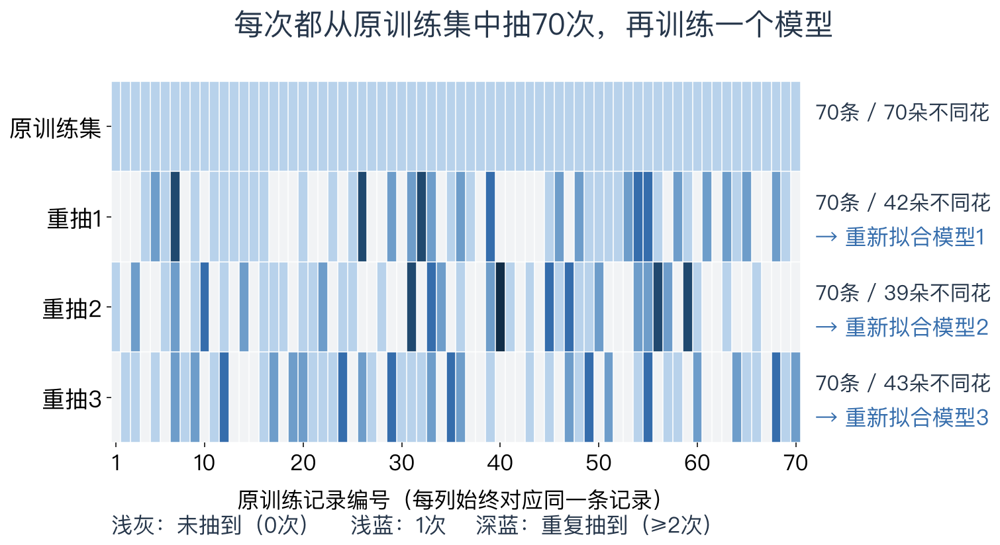

In [29]:
# [ref:l6-bootstrap-draws]
from bootstrap_ml_plots import plot_ml_draws

plot_ml_draws(boot_draws, assets_dir)
plt.show()


### 固定输入，比较不同重训模型的预测

预先固定探针输入：花瓣长度**4.8 cm**。所有模型都预测同一个输入属于维吉尼亚鸢尾（类别1）的概率，所以差异来自训练样本改变，而不是输入改变。

记原训练集模型在此点的预测为$\hat{\theta}$，第$b$份重抽训练集拟合后的预测为$\hat{\theta}^{*(b)}$。Bootstrap标准误差用这B次预测的样本标准差估计：

$$\widehat{\mathrm{SE}}_{\mathrm{boot}}(\hat{\theta})=\sqrt{\frac{1}{B-1}\sum_{b=1}^{B}(\hat{\theta}^{*(b)}-\overline{\hat{\theta}^{*}})^2}.$$

这里不再除以$\sqrt{B}$。它近似描述固定输入下**预测概率估计量对训练抽样的敏感程度**，不是准确率，也不是标签自身的随机性。下面不构造置信区间，预测最小值和最大值也不是95%区间。


In [30]:
# [ref:l6-bootstrap-stats]
boot_probe_predictions = np.array([m.predict_proba([[boot_probe]])[0, 1] for m in boot_models])
boot_curves = np.array([m.predict_proba(boot_grid)[:, 1] for m in boot_models])
bootstrap_summary = {
    "task": "training_bootstrap_logistic", "n_train": boot_n, "n_holdout": len(boot_eval_idx),
    "B": boot_B, "seed": SEED, "probe_petal_length_cm": boot_probe,
    "probability_mean": float(boot_probe_predictions.mean()),
    "probability_bootstrap_se": float(boot_probe_predictions.std(ddof=1)),
}
print(f"同一输入的预测均值：{boot_probe_predictions.mean():.1%}")
print(f"预测波动（标准差）：{boot_probe_predictions.std(ddof=1)*100:.2f}个百分点")
assert np.all((boot_probe_predictions >= 0) & (boot_probe_predictions <= 1))  # 概率必须在0到1之间


同一输入的预测均值：43.7%
预测波动（标准差）：6.17个百分点


### 先看概率曲线，再看同一点的预测分布

上图画前30个模型的曲线，避免200条线堆叠；下图使用全部200个模型在4.8 cm处的预测。黑色虚线是原70条训练记录拟合的参考模型，不是已知真函数。波动较小也不保证没有偏差或预测一定正确。


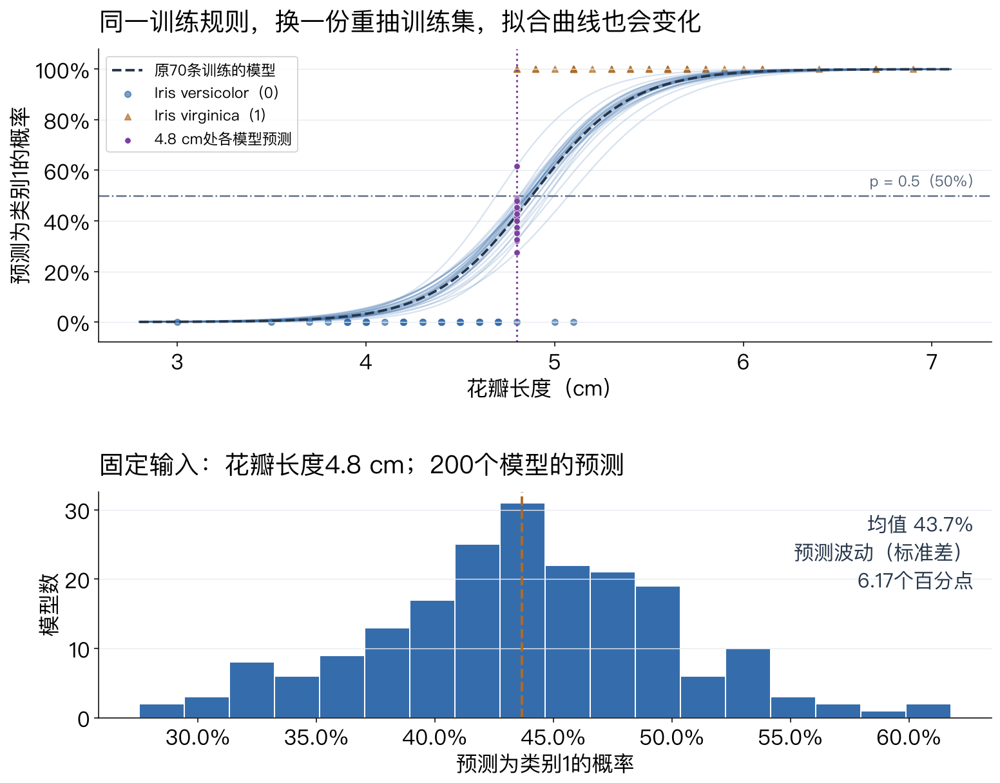

In [31]:
# [ref:l6-bootstrap-distribution]
from bootstrap_ml_plots import plot_ml_predictions
from bootstrap_plots import render_bootstrap_formulas

plot_ml_predictions(boot_X_train, boot_y_train, boot_grid, boot_curves,
                    boot_probe, boot_probe_predictions, boot_reference_curve, assets_dir)
plt.show()
render_bootstrap_formulas(assets_dir)


### 袋外记录：评价这一轮训练的模型

本轮一次都没抽中的原训练记录称为**袋外样本（out-of-bag, OOB）**。用它们评价本轮模型，而不能用本轮已抽中的训练记录充当独立评价。独立留出的30条是另一批数据，不是袋外记录。

任一训练记录一次没被选中的概率为$1-1/n$，连续n次都没被选中的概率为$(1-1/n)^n$，也就是袋外比例的期望；n较大时趋近$e^{-1}\approx36.8\%$，不是每轮固定值。


第1轮袋外记录数： 28 ；本轮袋外准确率： 1.0
袋外比例的期望： 0.3652


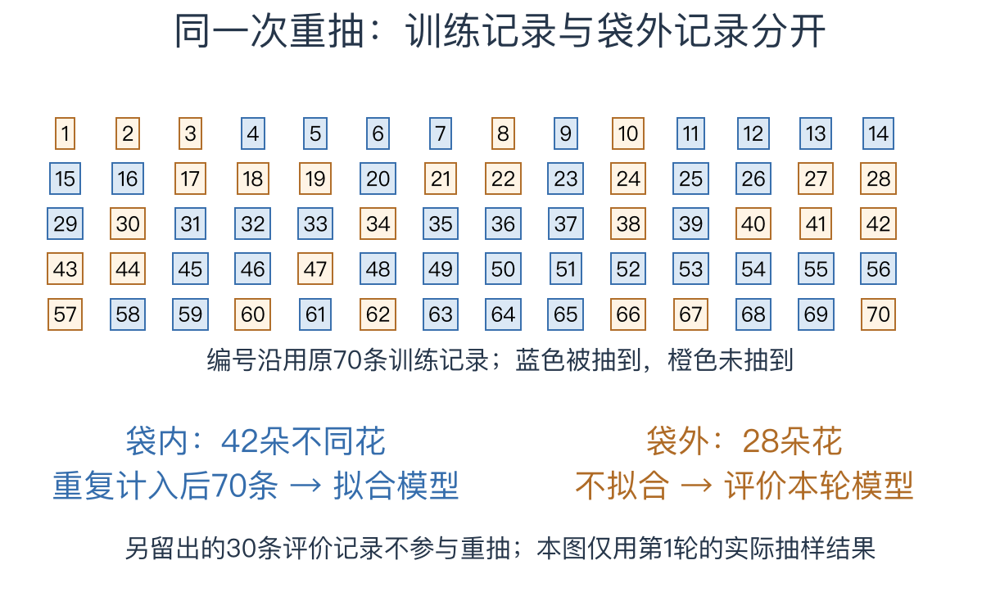

In [32]:
# [ref:l6-bootstrap-oob]
from bootstrap_ml_plots import plot_ml_oob

boot_first_counts = np.bincount(boot_draws[0], minlength=boot_n)
boot_oob_mask = boot_first_counts == 0
boot_oob_accuracy = boot_models[0].score(boot_X_train[boot_oob_mask], boot_y_train[boot_oob_mask])
bootstrap_summary.update(first_oob_count=int(boot_oob_mask.sum()), first_oob_accuracy=float(boot_oob_accuracy))
print("第1轮袋外记录数：", boot_oob_mask.sum(), "；本轮袋外准确率：", round(boot_oob_accuracy, 4))
print("袋外比例的期望：", round((1 - 1/boot_n)**boot_n, 4))
plot_ml_oob(boot_draws[0], assets_dir)
plt.show()


**与CV和Bagging的关系**：本课用CV评价、选择模型，用训练Bootstrap观察模型波动；两者用途并非互斥。Bagging进一步汇总这些重训模型的预测，第7讲再展开；这里不宣称对Logistic回归一定有提升。

**假设与边界**：普通逐条重抽基于独立同分布框架；同一用户的重复记录可按组重抽，时间序列可按块重抽。Iris的类别配比是数据集的采样设计，不能直接代表自然类比例。重抽不能修复系统性样本偏差或数据泄漏。单轮袋外成绩也不能当成整个选择过程的独立最终证据。

**参考资料**：[sklearn Bagging说明](https://scikit-learn.org/stable/modules/ensemble.html#bagging-meta-estimator)、[ISLP第5章实验](https://islp.readthedocs.io/en/latest/labs/Ch05-resample-lab.html)。课末保留均值Bootstrap作为可选统计学基础演示。


## 把候选 `C` 交给开发集内五折

使用1437条开发数据与相同分层五折，比较从0.0001到10000、按10倍递增的九档C，与课件验证曲线采用相同候选。`GridSearchCV`为每个候选拟合五个模型，并保存逐折训练与验证结果。后面的验证曲线直接复用这一次计算，不再重复拟合重叠候选。

In [33]:
# [ref:l6-selection-data]
from sklearn.model_selection import GridSearchCV
print("开发数据:", X_develop.shape, "预留数据:", X_reserved.shape)

开发数据: (1437, 64) 预留数据: (360, 64)


In [34]:
# [ref:l6-selection-model]
selection_model = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000, random_state=SEED)),
])
print("模型:", selection_model)

模型: Pipeline(steps=[('scale', StandardScaler()),
                ('logistic',
                 LogisticRegression(max_iter=1000, random_state=42))])


In [35]:
# [ref:l6-search]
selection_search = GridSearchCV(
    selection_model,
    {"logistic__C": CANDIDATES_CV},
    scoring="accuracy",
    cv=cv5,
    return_train_score=True,
    n_jobs=1,
)
selection_search.fit(X_develop, y_develop)
print(f"已完成{len(CANDIDATES_CV)}个候选，每个候选采用相同五折。")

已完成9个候选，每个候选采用相同五折。


In [36]:
# [ref:l6-search-table]
selection_results = pd.DataFrame(selection_search.cv_results_).sort_values("param_logistic__C")
cv_table_for_plot = selection_results[["param_logistic__C", "mean_train_score",
    "mean_test_score", "std_test_score", "rank_test_score"]].rename(columns={
    "param_logistic__C": "C", "mean_train_score": "训练准确率均值",
    "mean_test_score": "CV准确率均值", "std_test_score": "CV折标准差", "rank_test_score": "名次"})
cv_table = cv_table_for_plot  # 统一候选表，保留旧变量名供维护工具引用。
display(cv_table_for_plot.round(4))
print("开发集选择的C:", selection_search.best_params_["logistic__C"],
      "；这是九档候选中的选择结果，不是独立测试分数。")

,C,训练准确率均值,CV准确率均值,CV折标准差,名次
0,0.0001,0.8438,0.8330,0.0191,9
1,0.0010,0.9123,0.8991,0.0133,8
2,0.0100,0.9565,0.9436,0.0097,7
3,0.1000,0.9892,0.9631,0.0102,3
4,1.0000,0.9997,0.9680,0.0074,1
5,10.0000,1.0000,0.9666,0.0057,2
6,100.0000,1.0000,0.9631,0.0087,4
7,1000.0000,1.0000,0.9617,0.0096,5
8,10000.0000,1.0000,0.9610,0.0089,6


开发集选择的C: 1 ；这是九档候选中的选择结果，不是独立测试分数。


### 学习曲线：增加训练数据有帮助吗？

固定 `C=1`、同一条标准化Pipeline和原来的分层5折划分，只改变每折使用的训练记录数。将训练量加密为14个取点；相同折内按原训练索引取逐渐增长的前缀，验证成员保持不变，每次从头拟合标准化与模型。

**数据上限**：digits共1797条，开发集1437条，预留360条不参与此实验。5折训练块有1149或1150条，学习曲线使用共同可比的最大训练量1149条；增加取点不等于新增真实数据，也不把预留样本挪来训练。


In [37]:
# [ref:l6-learning]
from sklearn.model_selection import learning_curve

learning_model = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(C=1, max_iter=1000, random_state=SEED)),
])
# 比例相对于每折最大训练量；保留旧取点，并加密小样本与接近上限的区间。
learning_fractions = [.1, .15, .2, .25, .3, .4, .5, .6, .7, .8, .85, .9, .95, 1.0]
learning_sizes, learning_train, learning_valid = learning_curve(
    learning_model, X_develop, y_develop, train_sizes=learning_fractions,
    cv=cv5, scoring="accuracy", n_jobs=1, shuffle=False, error_score="raise",
)
assert learning_valid.shape == (14, 5)  # 每行一个训练量，每列一折验证结果


### 不只读均值：同时查看每一折

下面两表分别保存训练与验证的逐折准确率。图中的5条细线对应5折验证结果，粗橙线为验证均值，蓝色虚线为训练均值；折间差异不是置信区间，5折训练数据也不是彼此独立的。


In [38]:
learning_table = pd.DataFrame({
    "每折训练样本数": learning_sizes,
    "训练准确率": learning_train.mean(axis=1),
    "CV准确率": learning_valid.mean(axis=1),
})
# 不把5折压成一个数：每列对应固定的一折，便于检查均值背后的差异。
learning_train_folds = pd.DataFrame(learning_train, index=learning_sizes,
                                  columns=[f"训练折{i+1}" for i in range(5)])
learning_valid_folds = pd.DataFrame(learning_valid, index=learning_sizes,
                                  columns=[f"验证折{i+1}" for i in range(5)])
display(learning_table.round(4))
display(learning_train_folds.round(4))
display(learning_valid_folds.round(4))


,每折训练样本数,训练准确率,CV准确率
0,114,1.0000,0.9026
1,172,1.0000,0.9144
2,229,1.0000,0.9241
3,287,1.0000,0.9290
4,344,1.0000,0.9394
5,459,1.0000,0.9499
6,574,1.0000,0.9534
7,689,1.0000,0.9548
8,804,1.0000,0.9596
9,919,1.0000,0.9659


,训练折1,训练折2,训练折3,训练折4,训练折5
114,1.0,1.0000,1.0,1.0,1.0
172,1.0,1.0000,1.0,1.0,1.0
229,1.0,1.0000,1.0,1.0,1.0
287,1.0,1.0000,1.0,1.0,1.0
344,1.0,1.0000,1.0,1.0,1.0
459,1.0,1.0000,1.0,1.0,1.0
574,1.0,1.0000,1.0,1.0,1.0
689,1.0,1.0000,1.0,1.0,1.0
804,1.0,1.0000,1.0,1.0,1.0
919,1.0,1.0000,1.0,1.0,1.0


,验证折1,验证折2,验证折3,验证折4,验证折5
114,0.8854,0.9167,0.8780,0.9024,0.9303
172,0.9097,0.9271,0.9024,0.9024,0.9303
229,0.9375,0.9271,0.9094,0.9164,0.9303
287,0.9410,0.9271,0.9268,0.9129,0.9373
344,0.9444,0.9514,0.9268,0.9129,0.9617
459,0.9479,0.9479,0.9512,0.9373,0.9652
574,0.9549,0.9618,0.9582,0.9268,0.9652
689,0.9549,0.9618,0.9512,0.9373,0.9686
804,0.9583,0.9549,0.9652,0.9477,0.9721
919,0.9653,0.9757,0.9652,0.9477,0.9756


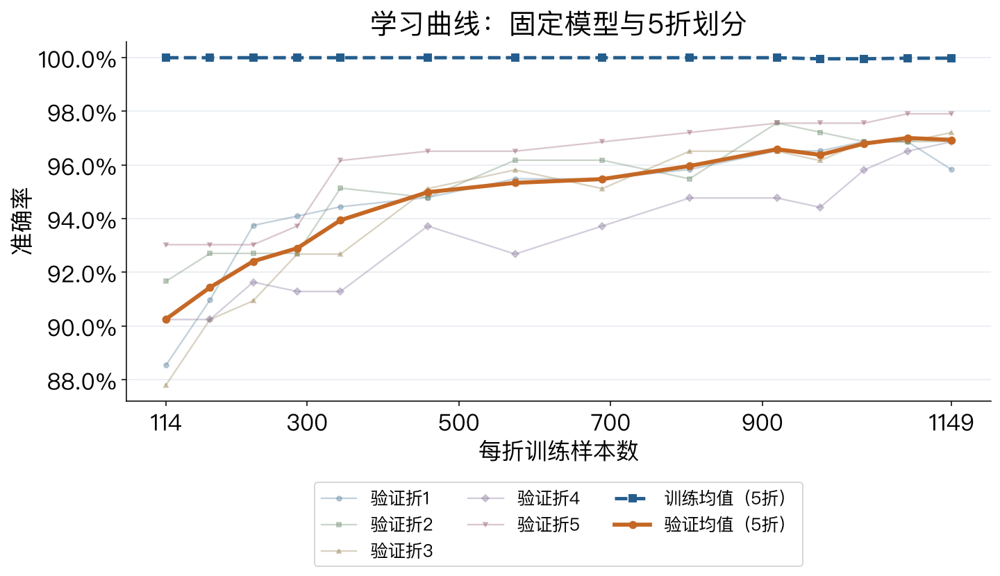

In [39]:
# 绘图与导出仅使用刚刚计算的14×5结果，不重新训练。
learning_curve_data = {
    "seed": SEED, "development_n": len(y_develop), "reserved_n": len(y_reserved),
    "fractions": learning_fractions, "sizes": learning_sizes.tolist(),
    "train_scores": learning_train.tolist(), "valid_scores": learning_valid.tolist(),
}
(assets_dir / "l6-learning-curve-data.json").write_text(
    json.dumps(learning_curve_data, ensure_ascii=False, indent=2), encoding="utf-8")
plot_learning(learning_table, assets_dir, fold_valid=learning_valid)
plt.show()


**怎样判断**：先看橙色验证均值是否整体改善，再看每折是否都有相近趋势，以及训练—验证差距是否缩小；不要求每折每一步都单调上升。图反映的只是现有训练量范围，不能外推更多数据必然提升多少。是否继续采样，还应结合误差分析、数据代表性和采集成本。


图已经在各实验旁展示；学习曲线改变训练量，接下来的验证曲线改变超参数C，二者使用相同五折但回答不同问题。

## 看证据：验证曲线与惩罚项对照

固定 `StandardScaler`→`LogisticRegression` 和同一分层五折，只改变 `C`。下面复用九档C的同一次五折搜索结果。验证曲线回答“哪个范围值得继续看”，不承担预留数据上的最终成绩。

### `penalty` 的版本边界

本环境是 scikit-learn 1.9.0；`LogisticRegression` 的 `penalty` 参数已弃用。用 `solver="saga"` 与 `l1_ratio=0/1` 表示 L2/L1，其他数据、折和评分保持不变。

图中点为均值，误差棒为五折标准差，不是置信区间。

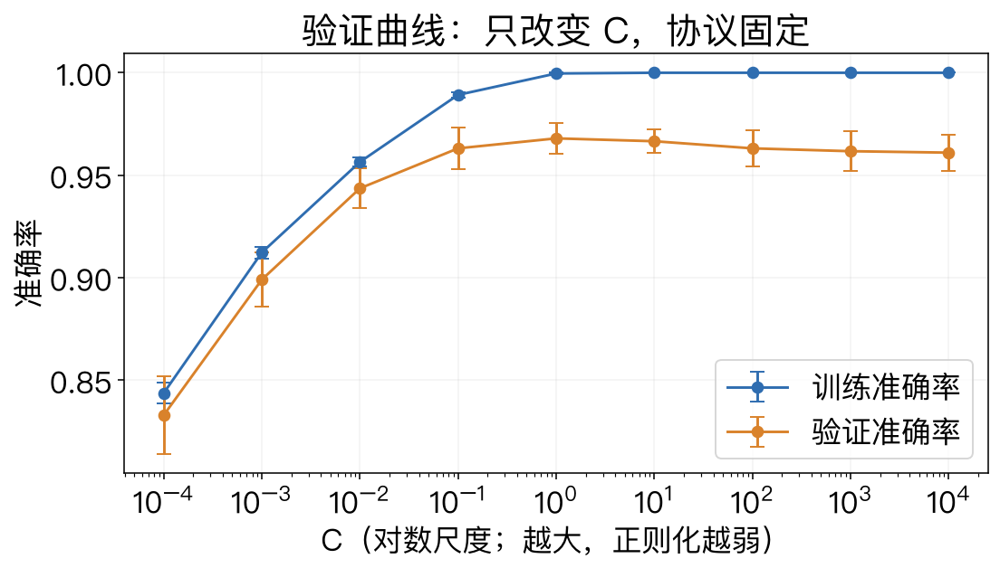

In [40]:
# [ref:l6-validation-curve]
from generalization_plots import validation_curve_plot, penalty_comparison_plot

# 不再调用validation_curve重新拟合，直接读取上面GridSearchCV的同一批五折结果。
curve_train = selection_results[[f"split{i}_train_score" for i in range(5)]].to_numpy()
curve_valid = selection_results[[f"split{i}_test_score" for i in range(5)]].to_numpy()
validation_curve_table = pd.DataFrame({"C": CANDIDATES_CV,
    "训练准确率均值": curve_train.mean(1), "训练准确率标准差": curve_train.std(1),
    "验证准确率均值": curve_valid.mean(1), "验证准确率标准差": curve_valid.std(1)})
assert np.allclose(validation_curve_table["验证准确率均值"], cv_table_for_plot["CV准确率均值"])
validation_curve_plot(validation_curve_table, assets_dir)
plt.show()

,惩罚,l1_ratio,验证准确率均值,验证准确率标准差
0,L2,0.0,0.9694,0.0086
1,L1,1.0,0.9638,0.0092


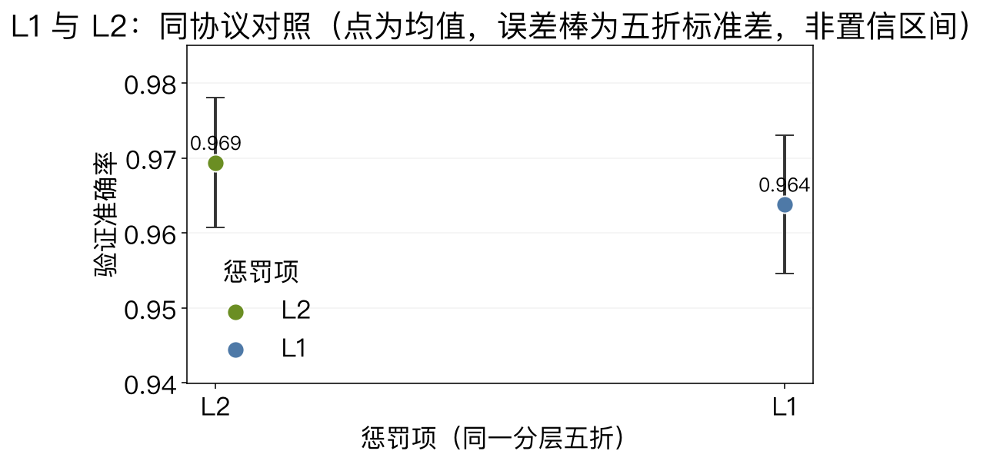

L1/L2 ConvergenceWarning: {'L2': 0, 'L1': 0}


In [41]:
# [ref:l6-penalty]
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import cross_validate

penalty_rows = []; penalty_convergence_warnings = {}
for name, ratio in [("L2", 0.0), ("L1", 1.0)]:
    penalty_model = Pipeline([("scale", StandardScaler()),
        ("logistic", LogisticRegression(l1_ratio=ratio, solver="saga",
                                         max_iter=10000, tol=1e-4, random_state=SEED))])
    with warnings.catch_warnings(record=True) as records:
        warnings.simplefilter("always", ConvergenceWarning)
        scores = cross_validate(penalty_model, X_develop, y_develop, cv=cv5,
                                scoring="accuracy", n_jobs=1)["test_score"]
    penalty_convergence_warnings[name] = sum(isinstance(r.message, ConvergenceWarning) for r in records)
    assert penalty_convergence_warnings[name] == 0
    penalty_rows.append({"惩罚": name, "l1_ratio": ratio,
        "验证准确率均值": scores.mean(), "验证准确率标准差": scores.std(ddof=0)})
penalty_table = pd.DataFrame(penalty_rows)
display(penalty_table.round(4)); penalty_comparison_plot(penalty_table, assets_dir); plt.show()
print("L1/L2 ConvergenceWarning:", penalty_convergence_warnings)

## 有预算地搜索：C与旋转增强幅度

沿用digits的64个像素，联合选择 `C=0.01、0.1、1` 与旋转角度 `angle=0°、10°、20°`，共9个组合。0°表示不增强；其余两档在每个训练折内加入±angle的两份旋转副本，保留原图，标签不变。角度过大可能改变数字含义；增强是否有益，由未增强的验证折判断。

下面的 `RotationLogistic` 是课程自定义分类器，不是sklearn内置API。它把增强放进 `fit`，再拟合标准化和Logistic；因此不会先增强再划分而让同源图片进入两侧。旋转使用双线性插值、黑色填充，保持8×8大小。

Grid枚举9组；Random从同一C的对数均匀范围和同三档角度中采样9组。两者使用同一分层3折、`refit=False`，各27次拟合。增强后的训练行数不同，拟合次数相同不代表成本相同。这里的训练分数是在原始训练折上计算的。

API参考：[sklearn自定义估计器](https://scikit-learn.org/stable/developers/develop.html)、[SciPy rotate](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.rotate.html)。


In [42]:
# [ref:l6-search-budget]
from scipy.ndimage import rotate
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import RandomizedSearchCV

# 自定义分类器：CV每次调用fit时，只收到当前训练折。
class RotationLogistic(ClassifierMixin, BaseEstimator):
    def __init__(self, C=1.0, angle=0):
        self.C = C
        self.angle = angle

    def fit(self, X, y):
        images = np.asarray(X, dtype=float).reshape(-1, 8, 8)
        versions = [images]
        if self.angle > 0:
            for signed_angle in [-self.angle, self.angle]:
                versions.append(rotate(images, signed_angle, axes=(1, 2),
                    reshape=False, order=1, mode="constant", cval=0, prefilter=False))
        train_X = np.concatenate(versions).reshape(-1, 64)
        train_y = np.tile(y, len(versions))  # 每份旋转副本沿用原图标签。
        self.model_ = Pipeline([("scale", StandardScaler()),
            ("logistic", LogisticRegression(C=self.C, max_iter=1000, random_state=SEED))])
        # 每份副本分摊原图权重，避免仅因行数变多而改变C的有效惩罚强度。
        weights = np.full(len(train_y), 1 / len(versions))
        self.model_.fit(train_X, train_y, logistic__sample_weight=weights)
        self.classes_ = self.model_.classes_
        self.n_features_in_ = 64
        return self

    def predict(self, X):
        return self.model_.predict(X)  # 验证时不旋转，也不重新拟合缩放器。

search_cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search_model = RotationLogistic()
search_C = [0.01, 0.1, 1.0]
search_angles = [0, 10, 20]
search_grid = GridSearchCV(search_model, {"angle": search_angles, "C": search_C},
    cv=search_cv3, scoring="accuracy", refit=False, return_train_score=True,
    error_score="raise", n_jobs=1)
search_grid.fit(X_develop, y_develop)
grid_warning_counts = {}  # 不再使用SelectKBest，没有需特殊处理的常量列警告。
print("Grid 候选/折/拟合:", len(search_grid.cv_results_["params"]), 3, 27)


Grid 候选/折/拟合: 9 3 27


In [43]:
# [ref:l6-search-random]
from scipy.stats import loguniform

search_random = RandomizedSearchCV(search_model,
    {"angle": search_angles, "C": loguniform(0.01, 1.0)}, n_iter=9,
    cv=search_cv3, scoring="accuracy", refit=False, return_train_score=True,
    random_state=SEED, n_jobs=1)
search_random.fit(X_develop, y_develop)
random_warning_counts = {}
grid_results, random_results = pd.DataFrame(search_grid.cv_results_), pd.DataFrame(search_random.cv_results_)
assert len(grid_results) == len(random_results) == 9
assert len({tuple(sorted(row.items())) for row in random_results["params"]}) == 9
search_columns = ["param_angle", "param_C", "mean_test_score", "std_test_score", "mean_fit_time"]
display(grid_results[search_columns].round(4)); display(random_results[search_columns].round(4))

,param_angle,param_C,mean_test_score,std_test_score,mean_fit_time
0,0,0.01,0.9436,0.0061,0.0039
1,10,0.01,0.9374,0.0078,0.0140
2,20,0.01,0.9248,0.0017,0.0135
3,0,0.10,0.9631,0.0035,0.0047
4,10,0.10,0.9569,0.0020,0.0150
5,20,0.10,0.9464,0.0055,0.0171
6,0,1.00,0.9645,0.0034,0.0051
7,10,1.00,0.9569,0.0035,0.0188
8,20,1.00,0.9464,0.0060,0.0208


,param_angle,param_C,mean_test_score,std_test_score,mean_fit_time
0,0,0.0561,0.9603,0.0030,0.0052
1,0,0.0233,0.9541,0.0034,0.0041
2,10,0.1562,0.9582,0.0030,0.0155
3,20,0.0205,0.9353,0.0061,0.0146
4,0,0.0829,0.9617,0.0043,0.0046
5,20,0.1593,0.9492,0.0065,0.0172
6,10,0.0110,0.9374,0.0078,0.0132
7,10,0.2780,0.9589,0.0020,0.0156
8,0,0.0266,0.9548,0.0026,0.0039


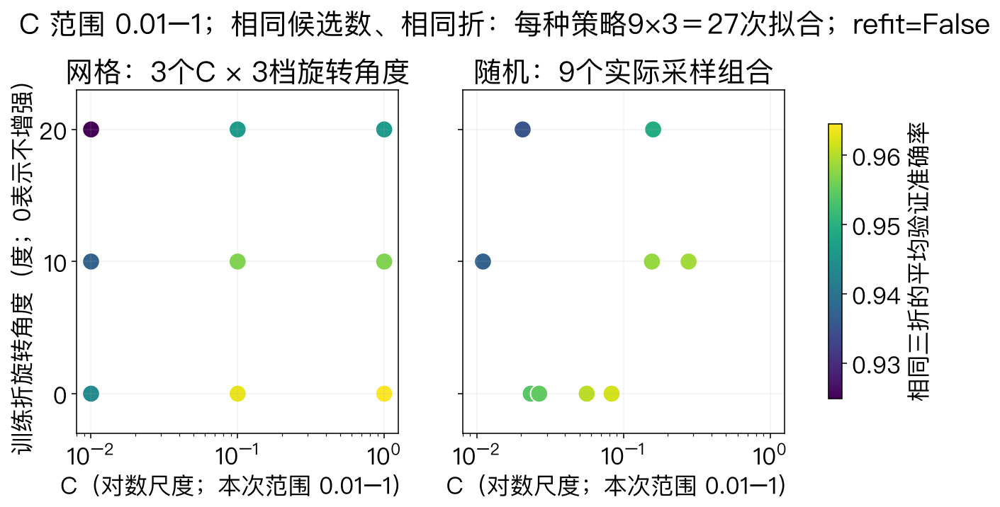

预算账本: {'cv_folds': 3, 'candidates_each': 9, 'fits_each': 27, 'refit': False, 'C_candidates': [0.01, 0.1, 1.0], 'angle_candidates_degrees': [0, 10, 20], 'random_C_distribution': 'loguniform(0.01, 1.0)', 'resource_unit': '每折原图数；angle>0时训练行数为3倍；另保留 mean_fit_time（秒）', 'same_fit_count_is_not_same_time': True, 'same_candidate_set': False, 'warning_counts': {'grid': {}, 'random': {}}}


In [44]:
from generalization_plots import search_budget_plot

search_budget_plot(grid_results, random_results, assets_dir); plt.show()
search_budget = {"cv_folds": 3, "candidates_each": 9, "fits_each": 27, "refit": False,
                 "C_candidates": search_C, "angle_candidates_degrees": search_angles,
                 "random_C_distribution": "loguniform(0.01, 1.0)",
                 "resource_unit": "每折原图数；angle>0时训练行数为3倍；另保留 mean_fit_time（秒）",
                 "same_fit_count_is_not_same_time": True,
                 "same_candidate_set": False,
                 "warning_counts": {"grid": grid_warning_counts, "random": random_warning_counts}}
print("预算账本:", search_budget)

### 读结果：增强是否有效也要验证

比较同一C下三档角度的分数，再比较整个网格。不能因为增强生成了更多训练图片，就假设效果必然更好；这些仍是开发集比较，不是独立测试结论。代码让每份副本分摊原图权重，各档训练权重总和相同，避免仅因训练行数增加而改变C的有效惩罚强度。


### 概念延伸｜早停与检查点负责不同的事

早停（Early Stopping）把训练轮次也作为需要验证的选择；检查点（Checkpoint）保存某一时刻的模型状态。按课件的Lightning示例，监控验证损失`val_loss`、取较小值：

- `EarlyStopping(min_delta=0.001, patience=10)`：相对其参考最佳值，下降超过0.001才清零计数；连续10次验证检查未达到要求，通知停止。次数不一定等于训练轮数。
- `ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1)`：在检查保存时出现新的最佳值，就保存最佳模型；它不采用早停的min_delta条件。
- 停止后显式加载`best_model_path`。早停本身不保存或恢复权重，最佳轮次也未必就是停止轮次。

例如参考值为0.5000，新值0.4995：若也低于检查点保存的最佳值，则可以保存；但这0.0005的下降不足以重置早停计数。验证集用于这些选择，最终测试数据仍不能参与。本章不运行Lightning；LogisticRegression的`max_iter`及求解收敛也不是这里基于验证损失的早停。

[Lightning：EarlyStopping](https://lightning.ai/docs/pytorch/stable/common/early_stopping.html) · [ModelCheckpoint](https://lightning.ai/docs/pytorch/stable/common/checkpointing_intermediate.html)。

## 类别重采样：改变训练比例，不改变评价数据

**随机过采样（Random Oversampling）**重复不足类别的记录；**随机下采样（Random Undersampling）**减少目标类别的记录。下采样不生成新样本，不能归为数据增强。**SMOTE（Synthetic Minority Over-sampling Technique）**在同类近邻之间合成特征点。

沿用前面的Iris二分类：只在原70条训练记录中保留35条类别0、随机保留10条类别1，使用花瓣长度和宽度两列。这是**人为减少训练侧类别1的教学情境**，不是Iris天然类别比例；原30条独立留出记录不参与下面的选择或评分。

需要依赖imbalanced-learn 0.14.2、sklearn-compat 0.1.6；见项目requirements.txt，不在教学单元格里静默安装或升级共享环境。

In [45]:
# [ref:l6-sampling-data]
import imblearn
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

sampling_rng = np.random.default_rng(SEED)
sampling_keep = np.r_[np.flatnonzero(boot_y_train == 0), sampling_rng.choice(
    np.flatnonzero(boot_y_train == 1), size=10, replace=False)]
sampling_X = boot_iris.data[boot_keep, 2:4][boot_train_idx][sampling_keep]
sampling_y = boot_y_train[sampling_keep]
assert set(boot_train_idx[sampling_keep]).isdisjoint(boot_eval_idx)
print("训练类别计数：", np.bincount(sampling_y), "| imbalanced-learn", imblearn.__version__)


训练类别计数： [35 10] | imbalanced-learn 0.14.2


### 1｜看三种方法怎样改变训练数据

先在这45条训练数据上拟合标准化器，再展示各方法的输出行数。这里为了说明机制设为两类等量，**不代表1∶1是最佳比例**。这一次拟合的缩放器只用于机制图，后面的CV会在每个训练折重新拟合，不能把这里的缩放结果送入CV。

In [46]:
# [ref:l6-sampling-counts]
sampling_scaler = StandardScaler().fit(sampling_X)
sampling_scaled = sampling_scaler.transform(sampling_X)
sampling_methods = {"随机过采样": RandomOverSampler(random_state=SEED),
    "随机下采样": RandomUnderSampler(random_state=SEED),
    "SMOTE": SMOTE(random_state=SEED, k_neighbors=3)}
sampling_count_rows = [{"方法": "原训练子集", "类别0": 35, "类别1": 10}]
for name, sampler in sampling_methods.items():
    resampled_x, resampled_y = sampler.fit_resample(sampling_scaled, sampling_y)
    count = np.bincount(resampled_y)
    sampling_count_rows.append({"方法": name, "类别0": int(count[0]), "类别1": int(count[1])})
display(pd.DataFrame(sampling_count_rows))


,方法,类别0,类别1
0,原训练子集,35,10
1,随机过采样,35,35
2,随机下采样,10,10
3,SMOTE,35,35


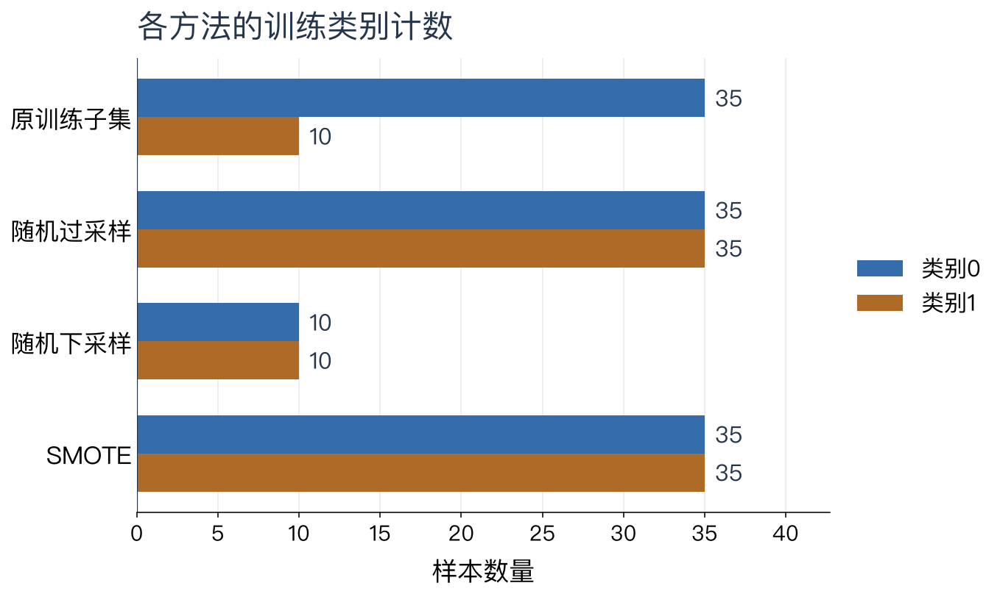

In [47]:
from augmentation_resampling_plots import plot_sampling_counts

plot_sampling_counts(sampling_count_rows, assets_dir)
plt.show()


### 2｜SMOTE为什么不是简单复制？

k表示候选同类近邻数；SMOTE从中随机选择邻居。xᵢ、xⱼ是同类样本的特征向量，λ决定线段上的位置：

$$x_{\mathrm{new}}=x_i+\lambda(x_j-x_i),\qquad \lambda\in[0,1].$$

下面用真实Iris训练记录示意一次λ=0.4的插值。近邻按标准化后的两维距离选取，绘图还原为cm；紫色菱形是这次指定插值的示意点，不冒充SMOTE随机输出中选出来的某条记录。普通SMOTE只依赖距离与插值，不能证明新点一定符合真实花的分布；类别编码也不能直接当连续数值插值。

In [48]:
# [ref:l6-smote-geometry]
from sklearn.neighbors import NearestNeighbors

smote_minority = sampling_scaled[sampling_y == 1]
smote_neighbors = NearestNeighbors(n_neighbors=4).fit(smote_minority)
smote_dist, smote_neighbor_ids = smote_neighbors.kneighbors(smote_minority[:1])
smote_j = next(int(j) for d, j in zip(smote_dist[0], smote_neighbor_ids[0]) if d > 1e-9)
smote_xi, smote_xj = sampling_scaler.inverse_transform(smote_minority[[0, smote_j]])
smote_lambda = .4
smote_xnew = smote_xi + smote_lambda * (smote_xj - smote_xi)
assert np.allclose(sampling_scaler.transform([smote_xnew])[0],
                   smote_minority[0] + smote_lambda * (smote_minority[smote_j] - smote_minority[0]))
print("同类两端点：", smote_xi, smote_xj, "| λ=0.4示意点：", smote_xnew)


同类两端点： [5.4 2.3] [5.3 2.3] | λ=0.4示意点： [5.36 2.3 ]


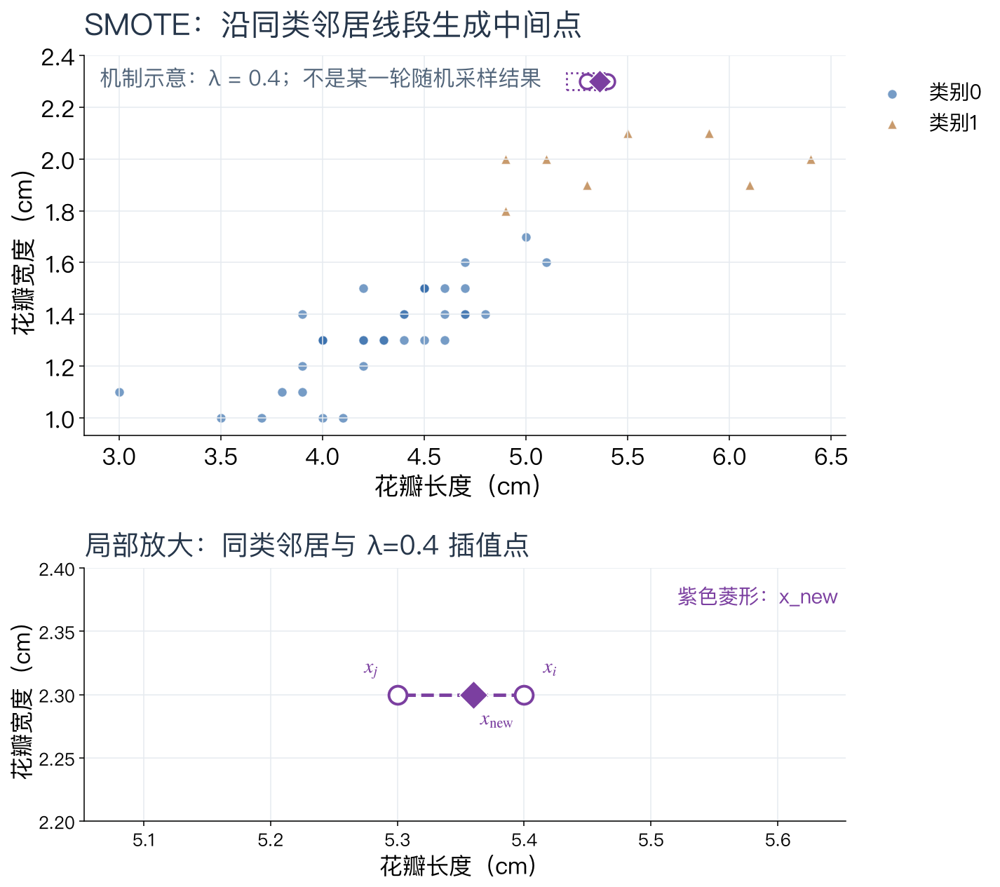

<Figure size 1484x217 with 0 Axes>

In [49]:
from augmentation_resampling_plots import plot_smote_geometry, render_smote_formula

plot_smote_geometry(sampling_X, sampling_y, smote_xi, smote_xj, smote_xnew, assets_dir)
render_smote_formula(assets_dir)
plt.show()


### 3｜采样器必须放进每轮训练流程

使用`imblearn.pipeline`，顺序为标准化→采样→模型。每折只在训练侧拟合缩放、采样及模型；验证侧保留原记录，不做过/下采样。`sklearn.pipeline.Pipeline`本身不能直接接收这些采样器的`fit_resample`。

下面只在45条教学子集内做分层3折，每折类别1只有3–4条，分数很不稳定。它用于核对API与防泄漏流程，不用于宣称某方法最佳。原30条留出和digits的360条预留数据都不评分。默认0.5仅作固定比较条件，采样改变训练比例后，概率与阈值须在代表目标分布的数据上重新检查。

In [50]:
# [ref:l6-sampling-pipeline]
from imblearn.pipeline import make_pipeline as make_sampling_pipeline
from sklearn.base import clone
from sklearn.metrics import make_scorer, precision_score, recall_score

sampling_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
sampling_scoring = {"AP": "average_precision",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0)}
sampling_pipelines = {"不重采样": make_sampling_pipeline(StandardScaler(),
    LogisticRegression(C=1, max_iter=1000))}
for name, sampler in sampling_methods.items():
    sampling_pipelines[name] = make_sampling_pipeline(StandardScaler(), clone(sampler),
        LogisticRegression(C=1, max_iter=1000))


In [51]:
sampling_cv_rows = []
for name, pipeline in sampling_pipelines.items():
    results = cross_validate(pipeline, sampling_X, sampling_y, cv=sampling_cv,
        scoring=sampling_scoring, n_jobs=1, return_estimator=True)
    for model, (train_idx, valid_idx) in zip(results["estimator"], sampling_cv.split(sampling_X, sampling_y)):
        assert np.all(model[0].n_samples_seen_ == len(train_idx))
        assert len(model.predict(sampling_X[valid_idx])) == len(valid_idx)
    sampling_cv_rows.append({"方法": name, **{
        metric: float(results["test_" + metric].mean()) for metric in sampling_scoring}})
sampling_cv_table = pd.DataFrame(sampling_cv_rows)
display(sampling_cv_table.round(3))


,方法,AP,Precision,Recall
0,不重采样,1.0,1.000,0.889
1,随机过采样,1.0,0.917,1.000
2,随机下采样,1.0,0.867,1.000
3,SMOTE,1.0,1.000,1.000


In [52]:
sampling_summary = {"source": "Iris original 70 training records only",
    "scenario": "artificially retain 35 class0 and 10 class1; two petal features",
    "seed": SEED, "counts": sampling_count_rows, "cv_folds": 3,
    "cv": sampling_cv_rows, "original_holdout_untouched": True,
    "geometry": {"xi": smote_xi.tolist(), "xj": smote_xj.tolist(),
                 "lambda": smote_lambda, "illustration": smote_xnew.tolist()},
    "environment": {"imbalanced_learn": imblearn.__version__}}
print("机制示例与折内流程已核对；不报告独立测试成绩。")


机制示例与折内流程已核对；不报告独立测试成绩。


**扩展阅读**：[SMOTE原论文](https://doi.org/10.1613/jair.953)、[过采样](https://imbalanced-learn.org/stable/over_sampling.html)、[下采样](https://imbalanced-learn.org/stable/under_sampling.html)、[先全数据采样的泄漏反例](https://imbalanced-learn.org/stable/common_pitfalls.html)。本例按官方训练折内流水线用法改编；图片自行绘制；本段使用sklearn内置Iris。后面图像增强使用独立的MNIST课堂案例。

传统分类增强通常保持标签；[Mixup](https://arxiv.org/abs/1710.09412)混合输入与标签，[CutMix](https://arxiv.org/abs/1905.04899)按区域面积混合标签，不能统一说成“所有增强都保持标签原样”。本节不实现这些深度学习扩展。

## 图像数据增强：加入合理的变化

SMOTE在同类特征近邻之间插值；**图像数据增强（Image Data Augmentation）**进一步利用图像的任务知识：数字的位置或倾角略变，类别通常不变。这里基于《Hands-On Machine Learning》第3章的MNIST＋KNN例子，增加平移、旋转及其组合对照，不再沿用前面8×8的digits。

MNIST为28×28灰度数字，像素0–255。本课堂版固定取官方训练部分中的5,000条训练、2,000条开发验证，seed=42；其余训练记录与官方测试集不用于本实验。KNN固定为4个近邻、距离加权，未按本次验证分数搜索参数。作者全量实验97.14%→97.63%是参考资料的结果，不是下面课堂子集的输出。

### 1｜自动读取或下载MNIST

优先复用课程data目录的`mnist/mnist.npz`，缺失时从Keras官方公开地址自动下载约11 MB，校验SHA-256后读取。无需安装TensorFlow或Keras。离线时保留该文件即可；来源、许可与校验值见data/README.md。

In [53]:
# [ref:l6-mnist-data]
from mnist_data import load_mnist_training

mnist_data_dir = project_root / "lessons/06-model-selection/notebook/data"
mnist_images, mnist_labels = load_mnist_training(mnist_data_dir)
print("官方训练部分：", mnist_images.shape, "；这里只返回训练图片与标签。")


官方训练部分： (60000, 28, 28) ；这里只返回训练图片与标签。


### 2｜先划分原图，再做增强

先按原图行号分层抽取训练与验证；同一原图的所有变体只用于训练。验证图片保持原样，不为了展示增强而变换评价条件。

In [54]:
# [ref:l6-augmentation-split]
mnist_fit_ids, mnist_valid_ids = train_test_split(
    np.arange(len(mnist_labels)), train_size=5000, test_size=2000,
    stratify=mnist_labels, random_state=SEED)
mnist_train_images = mnist_images[mnist_fit_ids]
mnist_y_train, mnist_y_valid = mnist_labels[mnist_fit_ids], mnist_labels[mnist_valid_ids]
mnist_X_valid = mnist_images[mnist_valid_ids].reshape(-1, 784).astype("float32") / 255
assert set(mnist_fit_ids).isdisjoint(mnist_valid_ids)
print({"原始训练": len(mnist_fit_ids), "开发验证": len(mnist_valid_ids)})


{'原始训练': 5000, '开发验证': 2000}


### 3｜定义增强策略A、B及其组合

**A：水平平移**，原图加左、右各1像素的版本，共15,000行。**B：小角度旋转**，原图加顺、逆时针各10°的版本，也为15,000行。**A+B**合并两组变体，原图只保留一份，共25,000行；不是把平移和旋转连续施加在同一张图上。

平移用`order=0`，整数位移不混合像素；旋转用`order=1`做双线性插值。`axes=(1,2)`只旋转高、宽两个维度，不混合不同样本；`reshape=False`保持28×28画布，超出部分裁去，空出位置填0。每个变体沿用原标签，但仍需检查笔画是否被破坏。

In [55]:
# [ref:l6-augmentation-build]
from scipy.ndimage import shift, rotate

mnist_directions = [("左移1 px", 0, -1), ("右移1 px", 0, 1)]
mnist_versions = [mnist_train_images]
for name, dy, dx in mnist_directions:
    mnist_versions.append(shift(mnist_train_images, (0, dy, dx),
        order=0, mode="constant", cval=0, prefilter=False))
for angle in [10, -10]:
    mnist_versions.append(rotate(mnist_train_images, angle, axes=(1, 2),
        reshape=False, order=1, mode="constant", cval=0, prefilter=False))
mnist_augmented = np.concatenate(mnist_versions)
mnist_horizontal = np.concatenate(mnist_versions[:3])
mnist_rotated = np.concatenate([mnist_versions[0], *mnist_versions[3:]])
mnist_y_augmented = np.tile(mnist_y_train, 5)
assert len(mnist_augmented) == 25000 and mnist_augmented.dtype == np.uint8


### 4｜先观察变换后的数字

下面展示训练侧首个6和首个9；左右平移属于A，顺、逆时针10°旋转属于B，不选择验证图片。轻微平移或倾斜可作为保留类别的候选，不表示任意角度旋转、镜像等变化也适合数字识别。

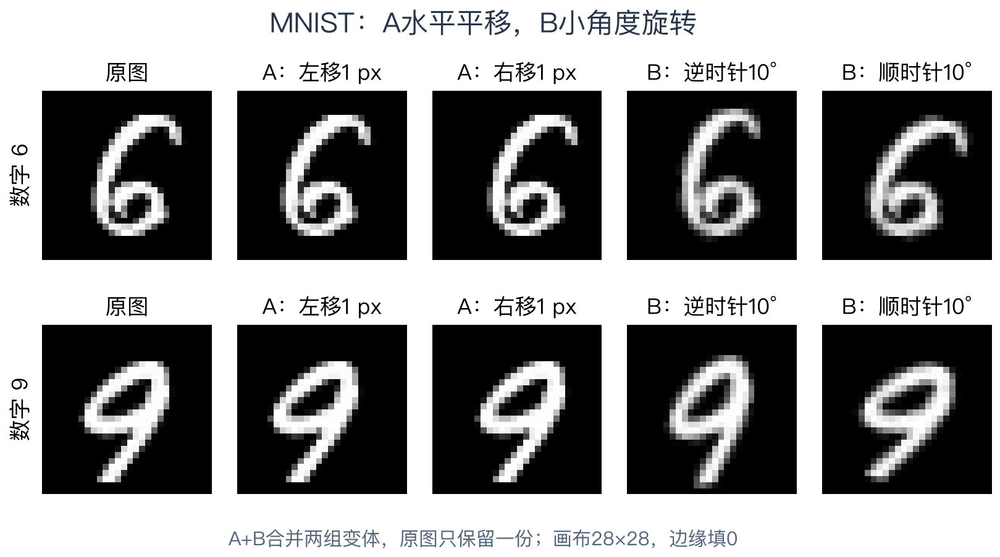

In [56]:
# [ref:l6-augmentation]
from mnist_augmentation_plots import plot_mnist_augmentation

mnist_example_ids = [np.flatnonzero(mnist_y_train == label)[0] for label in [6, 9]]
mnist_example_panels = [images[mnist_example_ids] for images in mnist_versions]
plot_mnist_augmentation(mnist_example_panels, [6, 9], assets_dir)
plt.show()


### 5｜同一个KNN，比较未增强、A、B与A+B

**K近邻分类（K-Nearest Neighbors，KNN）**按输入图与训练图的像素距离，找4个最近邻，距离越近投票权重越高。四种方案都用这个固定规则和同一验证集，像素统一除以255；不拟合StandardScaler，不选阈值。

A与B的训练行数相同，可比较平移与旋转；A+B的变体更多、计算量也更大。它若更好，不能据此把收益全部归因于两种策略的“协同效应”，也不能保证组合总是更好。1像素与10°是本次固定候选，不根据验证成绩反复搜索强度。

In [57]:
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits

mnist_X_train = mnist_train_images.reshape(-1, 784).astype("float32") / 255
mnist_baseline = KNeighborsClassifier(n_neighbors=4, weights="distance", algorithm="brute", n_jobs=1)
with threadpool_limits(limits=4):
    mnist_baseline.fit(mnist_X_train, mnist_y_train)
    mnist_baseline_pred = mnist_baseline.predict(mnist_X_valid)
print("未增强答对：", int((mnist_baseline_pred == mnist_y_valid).sum()), "/", len(mnist_y_valid))


未增强答对： 1877 / 2000


In [58]:
# [ref:l6-augmentation-results]
augmentation_rows = [{"方案": "未增强", "训练行数": 5000,
    "验证答对数": int((mnist_baseline_pred == mnist_y_valid).sum()),
    "验证准确率": float(accuracy_score(mnist_y_valid, mnist_baseline_pred))}]
for name, images in [("A：左右平移", mnist_horizontal),
                     ("B：旋转±10°", mnist_rotated),
                     ("A+B：平移与旋转", mnist_augmented)]:
    train_x = images.reshape(-1, 784).astype("float32") / 255
    train_y = np.tile(mnist_y_train, len(images) // len(mnist_y_train))
    model = KNeighborsClassifier(n_neighbors=4, weights="distance", algorithm="brute", n_jobs=1)
    with threadpool_limits(limits=4):
        model.fit(train_x, train_y)
        predicted = model.predict(mnist_X_valid)
    augmentation_rows.append({"方案": name, "训练行数": len(train_x),
        "验证答对数": int((predicted == mnist_y_valid).sum()),
        "验证准确率": float(accuracy_score(mnist_y_valid, predicted))})


In [59]:
augmentation_table = pd.DataFrame(augmentation_rows)
display(augmentation_table.round(4))
mnist_error_before = len(mnist_y_valid) - augmentation_rows[0]["验证答对数"]
mnist_error_after = len(mnist_y_valid) - augmentation_rows[-1]["验证答对数"]
augmentation_summary = {"dataset": "MNIST", "measured_gain": True,
    "records": augmentation_rows, "validation_size": len(mnist_y_valid),
    "error_reduction": 1 - mnist_error_after / mnist_error_before,
    "reserved_untouched": True, "seed": SEED,
    "protocol": "official training only; stratified 5000 train/2000 validation; k=4 distance; A horizontal +/-1px, B rotation +/-10 degrees (bilinear, zero fill, 28x28), A+B union (original once)",
    "strategies": {"A": "horizontal left/right 1 pixel", "B": "rotation clockwise/counterclockwise 10 degrees",
                   "A+B": "union of A and B variants; not sequential composition"}}
print(f"错误数：{mnist_error_before}→{mnist_error_after}；相对减少{augmentation_summary['error_reduction']:.1%}。")


,方案,训练行数,验证答对数,验证准确率
0,未增强,5000,1877,0.9385
1,A：左右平移,15000,1893,0.9465
2,B：旋转±10°,15000,1914,0.9570
3,A+B：平移与旋转,25000,1916,0.9580


错误数：123→84；相对减少31.7%。


**读结果**：对照表分别报告未增强、A、B、A+B的实际验证结果，先比较等量的A与B，再看增加变体后的组合表现。变换扩展了模型见过的位置变化；组合不保证更好，仍需验证。新增行不是独立采集的新观察，训练与验证仍须按原图隔离。

**与教材的区别**：本例使用5,000条训练和2,000条开发验证，新增平移、±10°旋转及合并对照；原教材是四向平移示例，使用全量MNIST并在官方测试集得到97.14%→97.63%。不要把两套实验的策略或准确率混为同一次比较。原版参考：[作者第3章Notebook，Data Augmentation](https://github.com/ageron/handson-ml3/blob/main/03_classification.ipynb)。

## 看样本选策略：哪些变化仍符合任务？

同一种变换，不一定适合不同数据集。下面用真实MNIST数字、Fashion-MNIST鞋靴和CIFAR-10车／马作课堂讨论，图中的变体只是候选策略，不报告它们的训练收益。Fashion-MNIST按衣物类别分类，水平翻转通常保留类别；上下翻转虽可能仍看得出类别，却不一定符合正常拍摄分布。

先问：①类别或标注是否改变？②是否像使用时可能遇到的图片？③关键笔画、轮廓或目标是否还在？通过这三项检查后，才用开发验证比较强度和组合。

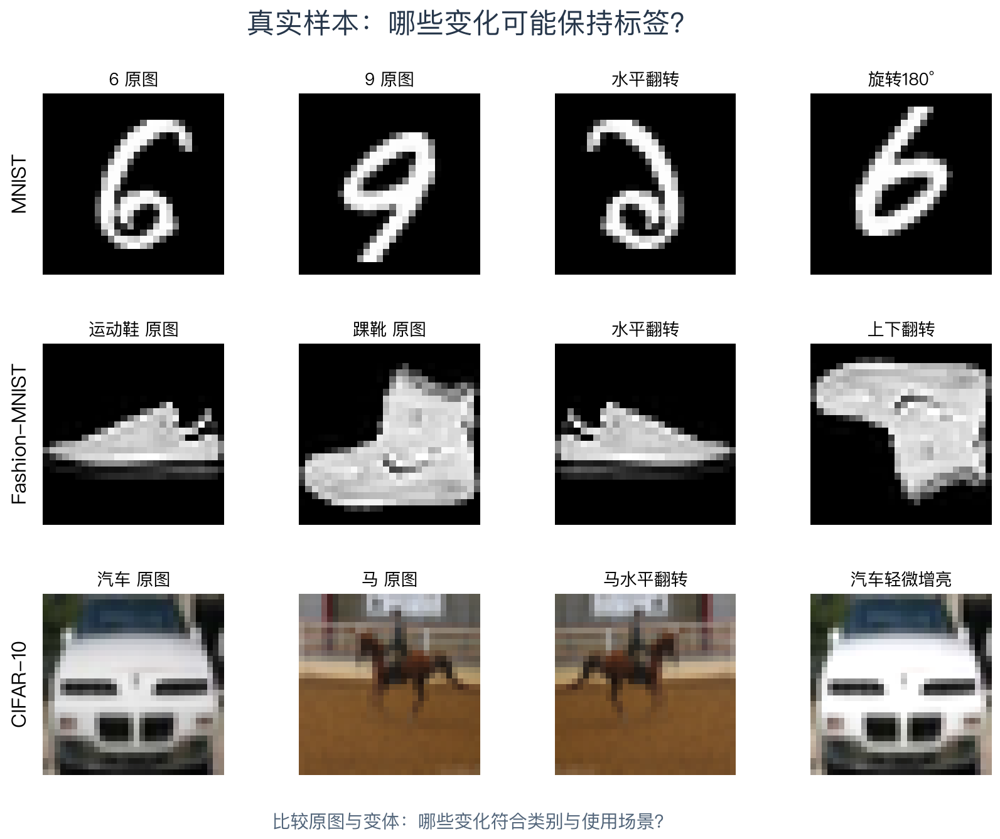

In [60]:
# [ref:l6-image-strategies]
from image_augmentation_examples import load_strategy_samples, plot_strategy_samples

strategy_samples = load_strategy_samples(mnist_data_dir, mnist_train_images, mnist_y_train)
plot_strategy_samples(strategy_samples, assets_dir)
plt.show()


**参考讨论**：MNIST可以候选小幅平移、缩放、小角度旋转；镜像及180°旋转可能破坏数字语义。Fashion-MNIST可候选水平翻转和适量平移，避免把鞋头、袖口等关键结构裁掉；上下翻转不是默认推荐。CIFAR-10的车／马可以候选水平翻转、小幅裁切及亮度/对比度变化，但目标必须保留；若换成按颜色分类的任务，颜色扰动也可能改变标签。

**扩展**：常见策略还包括噪声、模糊、遮挡；应模拟目标使用条件，不能一味加大强度。Mixup与CutMix同时混合输入和标签，不是所有增强都原样保持硬标签。本节只演示传统图像变换。

## 扩展选读｜少样本任务的支持集与查询集

5-way 1-shot 只描述一个任务的形状，不等于元学习。多个训练任务共享表示、初始化或适应规则；新任务只用支持集适应，查询集标签留到最后评分，不能用来挑适应步数或全局参数。这里不把固定表示＋近邻基线包装成元学习算法。

**与课件的关系**：课件介绍miniImageNet常见的64／16／20类互斥划分，再在新类别中组织任务。本Notebook只从digits抽一份5-way 1-shot协议示例，核对支持／查询互斥；没有执行miniImageNet基准，也没有训练元学习模型，不能据此报告新类别泛化成绩。

| 方法 | 怎样利用支持样本 | 新任务中更新什么 |
|---|---|---|
| 预训练表示＋小分类器 | 先提取特征，再训练新类别分类器 | 通常只更新分类器，也可微调表示 |
| 原型网络（ProtoNets） | 每类支持特征取均值，查询样本比较到原型的距离 | 标准做法计算原型，不在新任务更新网络 |
| MAML／Reptile | 跨任务学习便于适应的初始化，新任务做少量梯度更新 | 更新模型参数 |

这些方法可以组合。ProtoNets通常属于度量型元学习；固定表示上的近邻或原型规则本身不证明做过元学习。查询标签不能用于挑适应步数。详见课件少样本两页及其论文链接。

In [61]:
# [ref:l6-fewshot]
task_labels = np.arange(5)
support_indices = np.concatenate([np.flatnonzero(y == label)[:1] for label in task_labels])
query_indices = np.concatenate([np.flatnonzero(y == label)[1:3] for label in task_labels])
assert len(support_indices) == 5 and len(query_indices) == 10
assert set(support_indices).isdisjoint(set(query_indices))
fewshot_protocol_table = pd.DataFrame({"任务": ["digits 0–4"], "way": [5], "shot": [1],
    "支持索引": [support_indices.tolist()], "查询索引": [query_indices.tolist()],
    "支持/查询互斥": [True], "查询标签用途": ["最后评分；不参与适应或选参"]})
display(fewshot_protocol_table)
print("真实 digits 抽样:", len(support_indices), "个支持样本 +", len(query_indices), "个查询样本；不训练元学习模型。")

,任务,way,shot,支持索引,查询索引,支持/查询互斥,查询标签用途
0,digits 0–4,5,1,"[0, 1, 2, 3, 4]","[10, 20, 11, 21, 12, 22, 13, 23, 14, 24]",True,最后评分；不参与适应或选参


真实 digits 抽样: 5 个支持样本 + 10 个查询样本；不训练元学习模型。


## 模型复杂度：用Bootstrap观察训练波动

沿用正弦曲线作为**教学模拟**，但本节只生成一次30条原训练记录与240条独立留出记录。随后只从原训练集有放回抽样，不再生成新训练数据；这一步可直接用于已有的真实数据。留出集不参与抽样或拟合。

每份重抽训练集都用同一套索引拟合1、4、15阶多项式，公平比较复杂度。这里用固定留出集比较候选，不将它称作选择后的最终测试集。

In [62]:
# [ref:l6-complexity-bootstrap]
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

BOOT_N_TRAIN, BOOT_N_VALID, BOOT_REPEATS = 30, 240, 40
boot_degrees = [1, 4, 15]

# 仅在此处生成一次教学数据；换成真实数据时，只需替换这部分。
train_rng = np.random.RandomState(42)
boot_x_train = train_rng.uniform(-1, 1, BOOT_N_TRAIN)
boot_y_train = np.sin(np.pi * boot_x_train) + train_rng.normal(0, 0.2, BOOT_N_TRAIN)
valid_rng = np.random.RandomState(43)
boot_x_valid = valid_rng.uniform(-1, 1, BOOT_N_VALID)
boot_y_valid = np.sin(np.pi * boot_x_valid) + valid_rng.normal(0, 0.2, BOOT_N_VALID)

# 绘图网格不含标签，不用于计算留出MSE。
boot_grid = np.linspace(-1, 1, 240)
print("原训练集/独立留出集:", len(boot_y_train), len(boot_y_valid))

原训练集/独立留出集: 30 240


### 同一份训练数据，有放回抽40次

每次抽30条，特征与标签始终一起取。抽样索引只生成一次，三个阶数共享；原始训练集模型也拟合一次，作为橙线对照。

In [63]:
boot_rng = np.random.RandomState(44)
boot_indices = [boot_rng.choice(BOOT_N_TRAIN, BOOT_N_TRAIN, replace=True)
                for _ in range(BOOT_REPEATS)]
boot_unique_counts = np.array([len(np.unique(index)) for index in boot_indices])
boot_grid_predictions, boot_reference_predictions = {}, {}
boot_valid_predictions = {}  # 保存原模型的留出预测，供下一步复用
boot_complexity_rows = []

for degree in boot_degrees:
    grid_predictions, valid_predictions, valid_mses, train_mses = [], [], [], []
    for index in boot_indices:
        model = Pipeline([
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ("linear", LinearRegression()),
        ])
        model.fit(boot_x_train[index, None], boot_y_train[index])
        grid_predictions.append(model.predict(boot_grid[:, None]))
        # 用同一批未参与拟合的真实观测标签评价，不使用真函数或噪声方差。
        valid_prediction = model.predict(boot_x_valid[:, None])
        valid_predictions.append(valid_prediction)
        valid_mses.append(mean_squared_error(boot_y_valid, valid_prediction))
        train_mses.append(mean_squared_error(boot_y_train[index], model.predict(boot_x_train[index, None])))

    original_model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("linear", LinearRegression()),
    ]).fit(boot_x_train[:, None], boot_y_train)
    boot_grid_predictions[degree] = np.asarray(grid_predictions)
    boot_valid_predictions[degree] = np.asarray(valid_predictions)
    boot_reference_predictions[degree] = original_model.predict(boot_grid[:, None])
    boot_complexity_rows.append({
        "阶数": degree,
        "重抽训练MSE均值": float(np.mean(train_mses)),
        "留出MSE均值": float(np.mean(valid_mses)),
        "留出MSE中位数": float(np.median(valid_mses)),
        "留出MSE最大值": float(np.max(valid_mses)),
        "原训练集模型留出MSE": float(mean_squared_error(boot_y_valid, original_model.predict(boot_x_valid[:, None]))),
        "网格预测标准差均值": float(boot_grid_predictions[degree].std(axis=0, ddof=1).mean()),
    })
print("每份独特原记录数（最少/平均/最多）:",
      boot_unique_counts.min(), boot_unique_counts.mean(), boot_unique_counts.max())

每份独特原记录数（最少/平均/最多）: 16 18.925 23


### 比较训练贴合、留出误差与预测波动

均值汇总40个模型在**同一240条留出记录**上的MSE，不是先平均预测再算MSE；中位数和最大值帮助检查均值是否受极端拟合影响。重抽样本重复出现，独特记录少于30条，高阶拟合可能因此更不稳定。这是给定原训练集的Bootstrap实验，不能把它当作从真实总体独立取得40份训练集。

,阶数,重抽训练MSE均值,留出MSE均值,留出MSE中位数,留出MSE最大值,原训练集模型留出MSE,网格预测标准差均值
0,1,0.2298,0.2441,0.2396,3.098000e-01,0.2273,0.1294
1,4,0.0293,0.1673,0.0674,1.723900e+00,0.0595,0.1948
2,15,0.0059,206382.6474,1363.7412,5.668970e+06,3.3195,113.8443


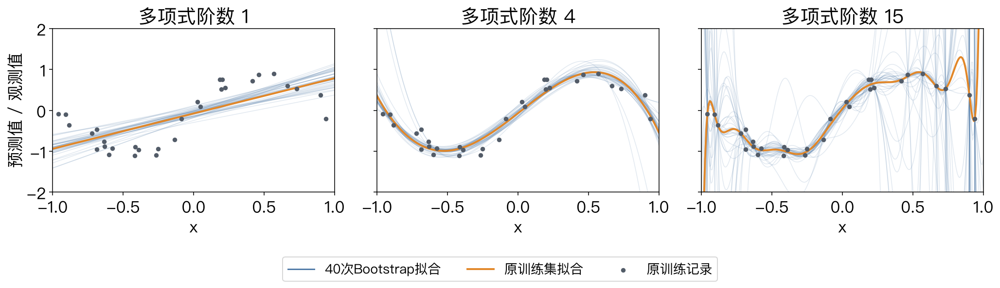

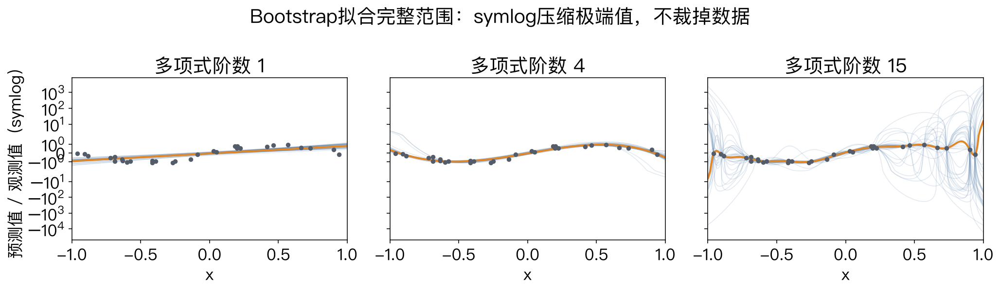

平均留出MSE（按阶数）: [{'阶数': 1, '留出MSE均值': 0.24413549772383103}, {'阶数': 4, '留出MSE均值': 0.16731432993343417}, {'阶数': 15, '留出MSE均值': 206382.6473896129}]


In [64]:
# [ref:l6-complexity-bootstrap-mse]
from selection_plots import plot_bootstrap_complexity

boot_complexity_table = pd.DataFrame(boot_complexity_rows)
display(boot_complexity_table.round(4))
assert np.isfinite(boot_complexity_table.to_numpy()).all()
assert all(pred.shape == (BOOT_REPEATS, len(boot_grid))
           for pred in boot_grid_predictions.values())
plot_bootstrap_complexity(boot_grid, boot_x_train, boot_y_train,
                         boot_grid_predictions, boot_reference_predictions, assets_dir)
plt.show()
bootstrap_complexity_summary = {
    "method": "pairs bootstrap; fixed independent validation set",
    "data": "one synthetic sin(pi*x) dataset; Gaussian observation noise std=0.2",
    "seeds": {"original_training": 42, "validation": 43, "bootstrap": 44},
    "n_train": BOOT_N_TRAIN, "n_valid": BOOT_N_VALID, "repeats": BOOT_REPEATS,
    "unique_training_records": {"min": int(boot_unique_counts.min()),
        "mean": float(boot_unique_counts.mean()), "max": int(boot_unique_counts.max())},
    "rows": boot_complexity_rows,
}
print("平均留出MSE（按阶数）:", boot_complexity_table[["阶数", "留出MSE均值"]].to_dict("records"))

**怎么解释？** 先对比1阶与4阶：直线的形状限制是否因增加复杂度而缓解？再看15阶：重抽训练误差虽低，留出误差和曲线波动是否反而增加？应一起看训练贴合、留出表现与波动，不凭阶数高低决定优劣。

**边界**：本实验只支持对这份数据、这三个候选的比较；Bootstrap不会创造新信息，也无法自动模拟未来分布变化。真实任务还需保证划分代表部署场景，选定方案后的最终表现应在未用于选择的数据上评价。

**继续分解同一批误差**：下面复用40个模型在同一240条留出记录上的预测，不重新训练；这里分解的是固定留出标签下的平均平方误差，不是课件“偏差²＋方差＋噪声”的总体风险分解；下面的独立模拟另用于解释理论关系。

## 正则化：同一组15阶特征，只改变惩罚

<!-- [ref:l6-regularization-effect] -->

复用上方 **30条原训练记录、240条固定验证记录**，不使用Bootstrap重抽数据。三次都用15阶多项式特征；展开后只在训练集拟合一次标准化，各模型使用同一套特征表示。

不加惩罚用 `LinearRegression`；L2惩罚用 `Ridge`。这里三个强度仅作教学对照，不宣称其中某个是最佳超参数，也不把看过的验证结果当独立测试结论。

Ridge最小化“残差平方和＋alpha×权重平方和”；本页课件采用平均平方损失，因此 **λ=alpha/n_train**，不惩罚截距。见[官方Ridge文档](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)。

本例w形状为(15,)，截距b为标量。4×4小图仅将w1—w15及b顺序排放，最后灰格b不参与L2惩罚；特征没有二维空间关系。


In [65]:
from sklearn.linear_model import Ridge

# 只在原训练集拟合预处理；三种强度共享同一组标准化特征。
reg_poly = PolynomialFeatures(degree=15, include_bias=False)
reg_scale = StandardScaler()
reg_train = reg_scale.fit_transform(reg_poly.fit_transform(boot_x_train[:, None]))
reg_valid = reg_scale.transform(reg_poly.transform(boot_x_valid[:, None]))
reg_grid = np.linspace(boot_x_train.min(), boot_x_train.max(), 400)
reg_grid_features = reg_scale.transform(reg_poly.transform(reg_grid[:, None]))
reg_alphas = [0.0, 0.1, 100.0]


In [66]:
# alpha=0时用普通最小二乘，正alpha用Ridge的SVD求解器。
reg_models, reg_predictions = {}, {}
for alpha in reg_alphas:
    if alpha == 0:
        estimator = LinearRegression()
    else:
        estimator = Ridge(alpha=alpha, solver="svd")
    estimator.fit(reg_train, boot_y_train)
    reg_models[alpha] = estimator
    reg_predictions[alpha] = estimator.predict(reg_grid_features)


In [67]:
# 训练MSE只含数据误差；验证MSE同样不加惩罚项。
reg_rows = []
for alpha, estimator in reg_models.items():
    reg_rows.append({"alpha": alpha, "lambda=alpha/n": alpha / len(boot_y_train),
        "训练MSE": mean_squared_error(boot_y_train, estimator.predict(reg_train)),
        "验证MSE": mean_squared_error(boot_y_valid, estimator.predict(reg_valid)),
        "权重平方和": float(np.sum(estimator.coef_ ** 2))})
reg_table = pd.DataFrame(reg_rows)
display(reg_table.style.format({"alpha": "{:g}", "lambda=alpha/n": "{:.5g}",
    "训练MSE": "{:.4f}", "验证MSE": "{:.4f}", "权重平方和": "{:.4g}"}))


,alpha,lambda=alpha/n,训练MSE,验证MSE,权重平方和
0,0,0,0.0103,3.3195,1.102e+07
1,0.1,0.0033333,0.0247,0.0823,4.862
2,100,3.3333,0.3687,0.3728,0.01373


In [68]:
# 直接取已拟合模型的15个标准化特征系数，不再训练。
reg_weight_vectors = np.vstack([reg_models[a].coef_ for a in reg_alphas])
reg_intercepts = np.asarray([reg_models[a].intercept_ for a in reg_alphas])
assert reg_weight_vectors.shape == (3, 15)  # 每行一个模型，每列一个特征
assert np.allclose(np.sum(reg_weight_vectors ** 2, axis=1), reg_table["权重平方和"])
coefficient_table = pd.DataFrame(np.vstack([reg_weight_vectors.T, reg_intercepts]),
    index=[f"w{j}" for j in range(1, 16)] + ["b（不惩罚）"],
    columns=[f"alpha={a:g}" for a in reg_alphas])
display(coefficient_table.style.format("{:.4g}"))


,alpha=0,alpha=0.1,alpha=100
w1,2.335,1.599,0.1059
w2,-1.389,-0.137,-0.009233
w3,-1.924,-1.315,0.04057
w4,5.37,0.2209,0.001175
w5,-64.94,-0.3494,0.01271
w6,24.91,0.1049,0.004959
w7,481.9,0.2288,-0.000145
w8,-181.9,0.01358,0.006171
w9,-1483,0.3629,-0.006512
w10,389.6,-0.0404,0.006357


In [69]:
# 核对本例随惩罚增强，训练误差不减、权重平方和不增。
assert np.all(np.diff(reg_table["训练MSE"]) >= -1e-10)
assert np.all(np.diff(reg_table["权重平方和"]) <= 1e-10)
regularization_demo = {"degree": 15, "n_train": len(boot_y_train),
    "n_valid": len(boot_y_valid), "grid_range": [float(reg_grid.min()), float(reg_grid.max())],
    "validation_outside_training_range": int(((boot_x_valid < reg_grid.min()) |
                                               (boot_x_valid > reg_grid.max())).sum()),
    "rows": reg_rows, "weights": reg_weight_vectors.tolist(),
    "intercepts": reg_intercepts.tolist(), "weight_shape": [15],
    "layout": "row-major 4x4; final grey b cell excluded from penalty"}
(assets_dir / "l6-regularization-effect-data.json").write_text(
    json.dumps(regularization_demo, ensure_ascii=False, indent=2), encoding="utf-8")
print("验证集中超出训练x范围的记录数：", regularization_demo["validation_outside_training_range"])


验证集中超出训练x范围的记录数： 16


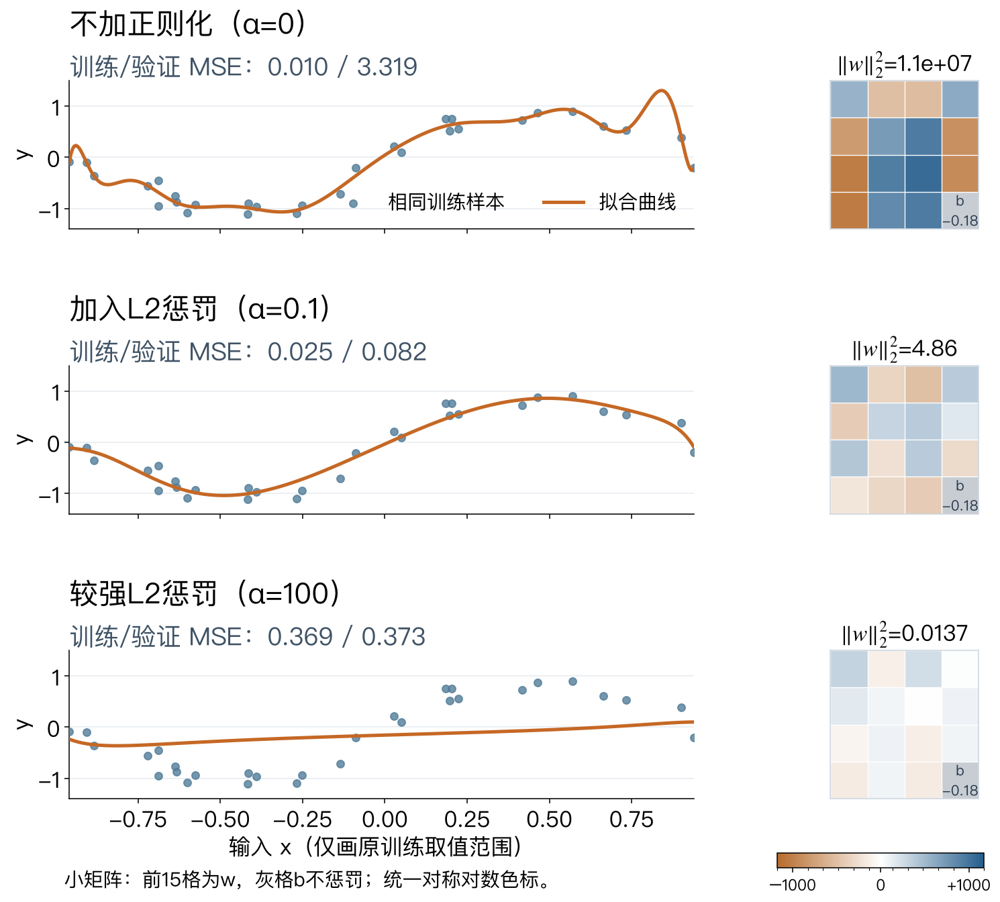

In [70]:
# 绘图helper只接收上述训练结果；不额外拟合模型。
from regularization_effect_plots import plot_regularization_effect
plot_regularization_effect(boot_x_train, boot_y_train, reg_grid,
                           reg_predictions, reg_table, assets_dir,
                           reg_weight_vectors, reg_intercepts)
plt.show()


**读图**：阶数始终是15，变化的是同一表示下的系数。加入L2惩罚后，权重平方和明显减小，训练贴合有所放松；本例验证MSE先下降，惩罚很强时又上升，说明不能只追求更小的权重。

**坐标与口径**：三幅图用相同坐标，只画原训练x取值范围，便于观察拟合变化；验证MSE仍使用全部240条记录，包括少量范围外记录。因此验证差异也涉及外推，不能全归因于训练范围内的过拟合。权重平方和只在本例固定的标准化特征表示下比较。

**停一下**：训练MSE变大是否就是正则化失败？不是，目标包含拟合误差与惩罚的权衡；是否改善泛化还需在未参与拟合的数据上比较。

**小矩阵读法**：前15格依次是w1—w15，末格灰色b不参与惩罚；使用同一对称对数色标显示多个量级的正负系数，不按颜色面积相加求范数。L2范数平方仍是15个权重平方之和。L2倾向整体收缩，不要求产生稀疏解，也不保证每个系数逐个单调减小。


### L1与L2：直接观察15个权重

<!-- [ref:l6-l1-l2-weights] -->

沿用同一训练集与标准化后的15个多项式特征，不重新拟合预处理。LASSO（最小绝对收缩与选择算子）使用L1惩罚，Ridge使用L2惩罚；下面强度只用于展示稀疏与收缩，不代表验证最优，也不表示两种API的alpha等价。截距不参与惩罚。

LASSO目标为MSE/2＋alpha×权重绝对值之和；Ridge目标为残差平方和＋alpha×权重平方和。


In [71]:
from sklearn.linear_model import Lasso

# 两模型共享训练数据与标准化特征，只改变惩罚形式和展示强度。
l1_demo = Lasso(alpha=0.01, max_iter=200000, tol=1e-9).fit(reg_train, boot_y_train)
l2_demo = Ridge(alpha=0.6, solver="svd").fit(reg_train, boot_y_train)
l1l2_weights = np.vstack([l1_demo.coef_, l2_demo.coef_])
l1l2_intercepts = np.array([l1_demo.intercept_, l2_demo.intercept_])
# 直接统计求解器输出的精确零，不把小的非零系数算成零。
l1l2_zeros = (l1l2_weights == 0).sum(axis=1)
display(pd.DataFrame(l1l2_weights.T, columns=["L1", "L2"],
                     index=[f"w{j}" for j in range(1, 16)]))
print("L1、L2精确零权重数：", l1l2_zeros)


,L1,L2
w1,1.377095,1.166767
w2,0.000000,-0.058556
w3,-0.997701,-0.466975
w4,0.000000,0.114785
w5,-0.000000,-0.329929
w6,0.000000,0.071848
w7,0.000000,-0.116510
w8,-0.000000,0.018398
w9,0.000000,0.002614
w10,-0.000000,-0.022767


L1、L2精确零权重数： [12  0]


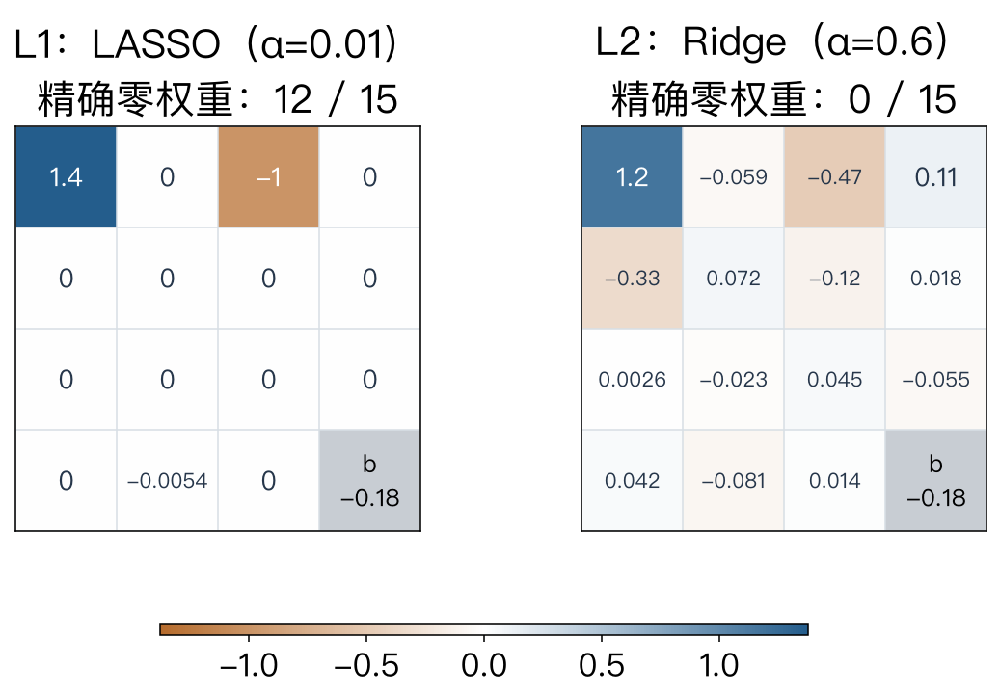

In [72]:
from regularization_effect_plots import plot_l1_l2_weights

# 绘图只读取上述实际拟合的系数，不另行训练。
plot_l1_l2_weights(l1l2_weights, l1l2_intercepts, assets_dir)
plt.show()


**读图**：同位置代表同一个标准化特征，白格中的0表示权重恰为0。灰格为截距，不参与惩罚。L1倾向稀疏，但不保证所有强度下都产生零；L2通常保留非零权重。相关多项式特征可互相替代，某个权重归零不证明该特征没有信息。


### 扩展｜Elastic Net：在L1与L2之间折中

弹性网（Elastic Net）在平方损失之外混合L1与L2惩罚。sklearn的`ElasticNet`采用：

$$J(w,b)=\frac{1}{2n}\sum_i(y_i-x_i^Tw-b)^2+\alpha\rho\lVert w\rVert_1+\frac{\alpha(1-\rho)}{2}\lVert w\rVert_2^2.$$

`alpha`控制总强度，`l1_ratio=ρ`控制混合比例，截距不惩罚。ρ=1对应LASSO；ρ=0时只剩L2项，但通常直接用Ridge。Ridge使用残差平方和，因此不要把两个API的同一alpha当成等强度。

需要稀疏时可尝试L1；相关特征使选择不稳定、又希望保留稀疏时，可尝试Elastic Net。它不保证优于L1或L2，应在同一训练内标准化、同一CV与评分规则下联合选择强度和混合比例。本段只说明接口与选择依据，不增加新的性能结论。[sklearn：ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html)。

### 平均留出误差：复用前面40个模型

每个留出输入的40次预测均值记为$\bar f(x_i)$，则：

$$\frac{1}{Bm}\sum_{b=1}^B\sum_{i=1}^m(\hat f_b(x_i)-y_i)^2
=\frac{1}{m}\sum_{i=1}^m(\bar f(x_i)-y_i)^2
+\frac{1}{m}\sum_{i=1}^m\frac{1}{B}\sum_{b=1}^B(\hat f_b(x_i)-\bar f(x_i))^2.$$

B=40个原模型，m=240条固定留出记录。右侧依次为**平均预测的留出MSE**和**各模型预测的方差，再对留出输入平均**；左侧为p22的“留出MSE均值”。

第一项对照带噪声标签，**不是理论Bias²，不能再额外加0.04**。方差用ddof=0，除以40；这与估计Bootstrap标准误差的ddof=1用途不同。


In [73]:
# [ref:l6-bootstrap-decomposition]
boot_decomposition_rows = []
for degree in boot_degrees:
    predictions = boot_valid_predictions[degree]  # 行为40个模型，列为240条留出记录
    average_prediction = predictions.mean(axis=0)
    average_mse = np.mean((predictions - boot_y_valid[None, :]) ** 2)
    ensemble_mse = np.mean((average_prediction - boot_y_valid) ** 2)
    prediction_variance = predictions.var(axis=0, ddof=0).mean()
    boot_decomposition_rows.append({"阶数": degree, "平均留出MSE": float(average_mse),
        "平均预测的留出MSE": float(ensemble_mse), "预测方差": float(prediction_variance)})
boot_decomposition_table = pd.DataFrame(boot_decomposition_rows)
display(boot_decomposition_table.round(4))


,阶数,平均留出MSE,平均预测的留出MSE,预测方差
0,1,0.2441,0.2265,0.0176
1,4,0.1673,0.0750,0.0923
2,15,206382.6474,3474.1842,202908.4632


In [74]:
# [ref:l6-bootstrap-decomposition-check]
left = boot_decomposition_table["平均留出MSE"].to_numpy()
right = (boot_decomposition_table["平均预测的留出MSE"] + boot_decomposition_table["预测方差"]).to_numpy()
assert np.allclose(left, right, rtol=1e-12, atol=1e-10)  # 两项和还原平均MSE
assert np.allclose(left, boot_complexity_table["留出MSE均值"])  # 与p22完全相同的预测
bootstrap_complexity_summary["holdout_decomposition"] = boot_decomposition_rows
(assets_dir / "l6-bootstrap-decomposition-data.json").write_text(
    json.dumps(boot_decomposition_rows, ensure_ascii=False, indent=2), encoding="utf-8")
print("两项和的最大数值误差：", float(np.max(np.abs(left-right))))


两项和的最大数值误差： 5.820766091346741e-11


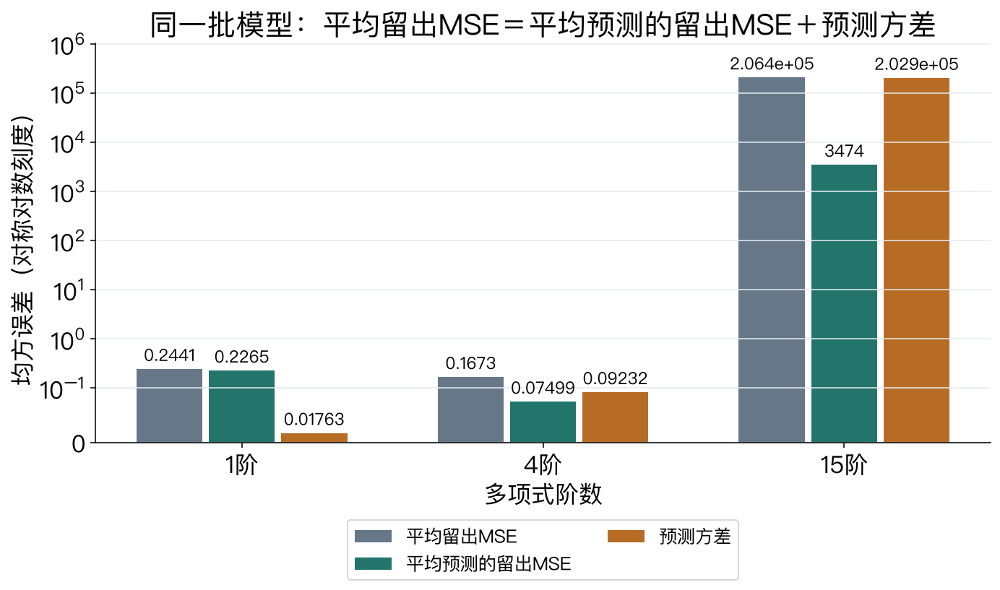

In [75]:
from selection_plots import plot_bootstrap_decomposition, render_holdout_decomposition_formula
plot_bootstrap_decomposition(boot_decomposition_table, assets_dir)
render_holdout_decomposition_formula(assets_dir)
plt.show()


**集成联系**：平均预测的留出MSE不大于各模型MSE的平均，差额就是预测方差。这是固定数据下平方损失的代数关系，不保证优于原训练集模型，也不能直接推广为分类投票改善。

**理论区别**：对真实训练集分布和新观测取期望，且新噪声独立、零均值，才有Bias²＋Variance＋噪声方差。课件“预测误差的三个来源”讲这条理论关系；下方独立模拟利用已知真函数演示，不能用上面的两项恒等式替代。[CSC311推导](https://www.teach.cs.toronto.edu/~csc311notes/bias_variance_decomposition/bv.html)。


以下是课件理论分解的可选数值演示。它独立生成训练集，与前面的Bootstrap实验不同，两套数值不混用。

## 选读：独立重复模拟，解释偏差与方差（不是Bootstrap）

下面是**教学模拟**，不是 digits 的结果。真函数固定为 `sin(πx)`，在 `[-1, 1]` 上对应 `[0, 1]` 的单周期；每次取 30 个训练样本，观测噪声标准差为 0.2，独立重复 40 次。主图只在 `[-0.9, 0.9]` 比较，以减少边界外推影响。

In [76]:
# [ref:l6-complexity]
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

COMPLEXITY_SEED, COMPLEXITY_REPEATS = 42, 40
COMPLEXITY_N_TRAIN, COMPLEXITY_NOISE_STD = 30, 0.2
degrees = [1, 4, 15]
x_grid = np.linspace(-0.9, 0.9, 240)
true_curve = np.sin(np.pi * x_grid)
print("内部比较区间:", (x_grid.min(), x_grid.max()), "| 噪声方差:", COMPLEXITY_NOISE_STD ** 2)

内部比较区间: (np.float64(-0.9), np.float64(0.9)) | 噪声方差: 0.04000000000000001


In [77]:
rng = np.random.RandomState(COMPLEXITY_SEED)
fit_predictions = {degree: [] for degree in degrees}
fit_models = {degree: [] for degree in degrees}
print("每次训练样本数/重复次数:", COMPLEXITY_N_TRAIN, COMPLEXITY_REPEATS)

每次训练样本数/重复次数: 30 40


### 先看一个模型，再重复取训练集

先固定一个四阶模型的结构；后面的循环只改变训练样本，不把训练过程藏进绘图函数。

In [78]:
single_model = Pipeline([
    ("poly", PolynomialFeatures(degree=4, include_bias=False)),
    ("linear", LinearRegression()),
])
print("单次示范模型:", single_model)

单次示范模型: Pipeline(steps=[('poly', PolynomialFeatures(degree=4, include_bias=False)),
                ('linear', LinearRegression())])


In [79]:
for repeat in range(COMPLEXITY_REPEATS):
    x_train = rng.uniform(-1, 1, COMPLEXITY_N_TRAIN)
    y_train = np.sin(np.pi * x_train) + rng.normal(0, COMPLEXITY_NOISE_STD, COMPLEXITY_N_TRAIN)
    for degree in degrees:
        model = Pipeline([("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                          ("linear", LinearRegression())])
        model.fit(x_train[:, None], y_train)
        fit_predictions[degree].append(model.predict(x_grid[:, None]))
        fit_models[degree].append(model)
print("每个阶数的拟合次数:", {degree: len(preds) for degree, preds in fit_predictions.items()})

每个阶数的拟合次数: {1: 40, 4: 40, 15: 40}


### 网格上的偏差²、方差与新观测 MSE

在固定内部网格上，平均预测与真函数的距离给偏差²；不同训练集产生的预测波动给方差；新的观测还含有噪声 `0.2²=0.04`。独立左侧先计算 `mean((prediction - truth)²) + 0.04`，再与右侧的偏差²、方差和噪声相加核对。

In [80]:
# [ref:l6-decomposition]
complexity_rows, complexity_components = [], {}
for degree in degrees:
    predictions = np.asarray(fit_predictions[degree])
    mean_prediction = predictions.mean(axis=0)
    bias_squared = (mean_prediction - true_curve) ** 2
    variance = predictions.var(axis=0)
    complexity_components[degree] = {"predictions": predictions,
        "mean_prediction": mean_prediction, "bias_squared": bias_squared,
        "variance": variance}
print("已拆出三种阶数的平均预测、偏差²和方差数组。")

已拆出三种阶数的平均预测、偏差²和方差数组。


In [81]:
for degree, comp in complexity_components.items():
    independent_lhs = np.mean((comp["predictions"] - true_curve[None, :]) ** 2)
    independent_lhs += COMPLEXITY_NOISE_STD ** 2
    rhs = np.mean(comp["bias_squared"] + comp["variance"] + COMPLEXITY_NOISE_STD ** 2)
    complexity_rows.append({"阶数": degree, "平均偏差²": comp["bias_squared"].mean(),
        "平均方差": comp["variance"].mean(), "噪声方差": COMPLEXITY_NOISE_STD ** 2,
        "预计新观测MSE": independent_lhs, "恒等式右侧": rhs})

,阶数,平均偏差²,平均方差,噪声方差,预计新观测MSE,恒等式右侧
0,1,0.1577,0.0137,0.04,0.2114,0.2114
1,4,0.0027,0.0150,0.04,0.0577,0.0577
2,15,13.8446,296.9546,0.04,310.8392,310.8392


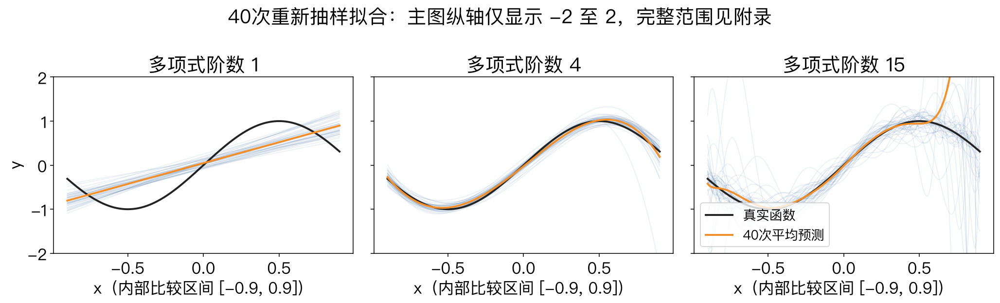

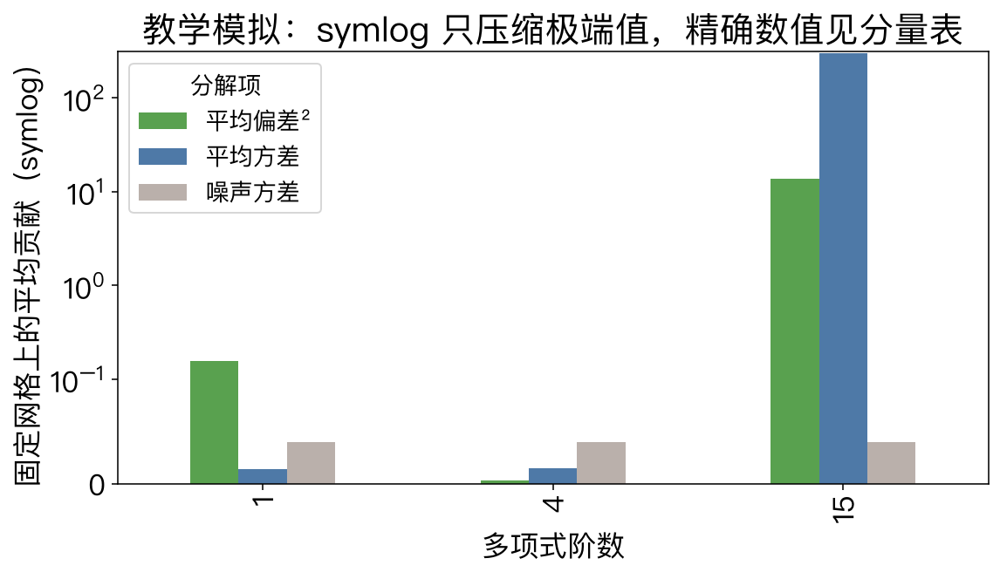

独立左侧与右侧最大误差: 2.7755575615628914e-17


In [82]:
# [ref:l6-complexity-mse]
complexity_table = pd.DataFrame(complexity_rows)
display(complexity_table.round(4))
plot_complexity(x_grid, true_curve, complexity_components, assets_dir)
plot_decomposition(complexity_table, assets_dir)
plt.show()
decomposition_max_error = max(abs(complexity_table["预计新观测MSE"] - complexity_table["恒等式右侧"]))
# 独立左侧与偏差²+方差+噪声右侧应一致。
assert decomposition_max_error < 1e-10
print("独立左侧与右侧最大误差:", decomposition_max_error)

**复杂度是否越高越好？** 固定每次30条训练数据，1阶到4阶的新观测误差下降，继续升到15阶反而剧增。这里只比较本次三个候选，不能推广为“复杂模型必然更差”。

**指标口径**：因为模拟真函数已知，可直接计算每个预测相对真函数的平方误差，再加独立新噪声的方差0.04；表中“预计新观测MSE”平均了40次拟合与240个网格点，不是训练MSE，也不是实测验证标签上的样本MSE。

**读图**：黑线为真函数、浅蓝为各次拟合、橙线为平均预测。主图只显示y∈[−2,2]；15阶的极端震荡及完整范围保留在附录图，不能因裁剪而忽略其对平均平方误差的影响。真实数据通常不知道真函数，不能直接照此计算真实偏差与方差。

## 扩展选做｜特征选择与随机标签泄漏

随机标签实验保留为一个短诊断：先在全部样本上 `SelectKBest.fit` 会让标签信息穿过划分边界；把选择器放进 `Pipeline` 后，每个训练折才独立学习列。高分不是随机标签获得了稳定规律，而是评价已经被污染。

In [83]:
# [ref:l6-leakage]
from sklearn.feature_selection import SelectKBest
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, KFold

rng = np.random.RandomState(SEED)
X_random = rng.standard_normal((200, 10000))
y_random = rng.choice(2, 200)
X_rand_train, X_rand_valid, y_rand_train, y_rand_valid = train_test_split(
    X_random, y_random, random_state=SEED
)

In [84]:
leaky_selector = SelectKBest(k=25).fit(X_random, y_random)
X_random_selected = leaky_selector.transform(X_random)
print("全体选列后的形状:", X_random_selected.shape)
print("前5个列号:", leaky_selector.get_support(indices=True)[:5])

全体选列后的形状: (200, 25)
前5个列号: [ 955 1116 1260 1967 2283]


In [85]:
leaky_model = HistGradientBoostingClassifier(random_state=1)
leaky_model.fit(leaky_selector.transform(X_rand_train), y_rand_train)
leaky_train_score = leaky_model.score(leaky_selector.transform(X_rand_train), y_rand_train)
leaky_valid_score = leaky_model.score(leaky_selector.transform(X_rand_valid), y_rand_valid)
print("泄漏流程训练/验证:", round(leaky_train_score, 3), round(leaky_valid_score, 3))

泄漏流程训练/验证: 1.0 0.76


In [86]:
manual_selector = SelectKBest(k=25).fit(X_rand_train, y_rand_train)
X_manual_train = manual_selector.transform(X_rand_train)
X_manual_valid = manual_selector.transform(X_rand_valid)
manual_hgb = HistGradientBoostingClassifier(random_state=1)
manual_hgb.fit(X_manual_train, y_rand_train)
manual_valid_score = manual_hgb.score(X_manual_valid, y_rand_valid)
print("手工正确选列→训练→验证:", round(manual_valid_score, 3))

手工正确选列→训练→验证: 0.5


Pipeline留出: 0.5 | 默认分层五折: [0.475 0.45  0.4   0.35  0.475]


,流程,验证准确率
0,污染留出,0.76
1,手工修复留出,0.50
2,修复后五折CV,0.43


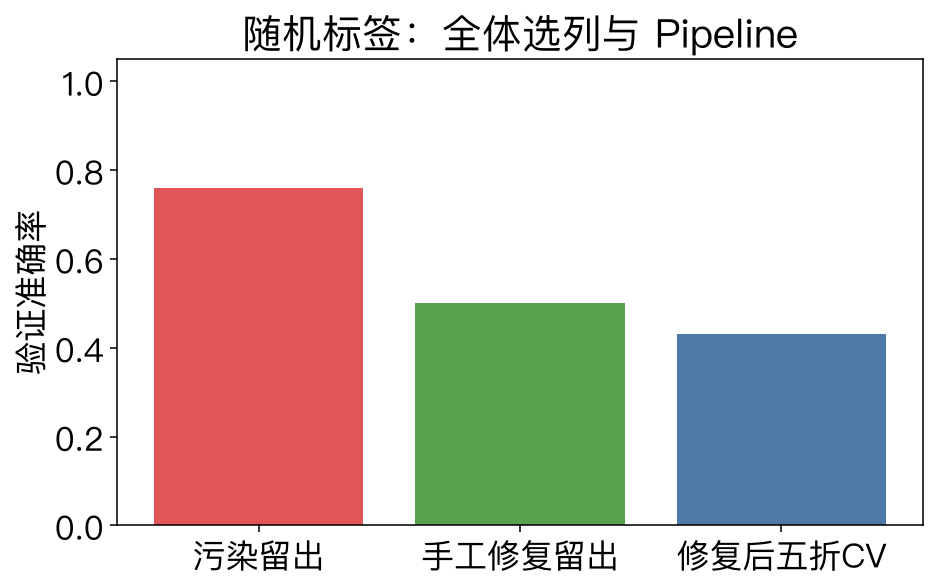

In [87]:
safe_model = Pipeline([
    ("select", SelectKBest(k=25)),
    ("classifier", HistGradientBoostingClassifier(random_state=1)),
])
safe_model.fit(X_rand_train, y_rand_train)
safe_holdout_score = safe_model.score(X_rand_valid, y_rand_valid)
safe_scores = cross_val_score(safe_model, X_random, y_random, cv=5, n_jobs=1)
# Pipeline 留出应与手工正确选列的留出分数一致。
assert np.isclose(safe_holdout_score, manual_valid_score)
leakage_table = pd.DataFrame({"流程": ["污染留出", "手工修复留出", "修复后五折CV"],
                              "验证准确率": [leaky_valid_score, manual_valid_score, safe_scores.mean()]})
print("Pipeline留出:", round(safe_holdout_score, 3), "| 默认分层五折:", np.round(safe_scores, 3))
display(leakage_table.round(3))
plot_leakage(leakage_table, assets_dir)
plt.show()

### 扩展选做｜划分敏感性与推断块

沿用前版的 14 个相邻推断块用于课堂演示，但 Notebook 明确写成“推断块”，不命名为真实书写者；公开加载结果没有逐样本 writer ID，故不能据此报告真实新 writer 性能。来源为 INRIA scikit-learn MOOC Sample grouping，CC-BY-4.0；上游版本与 manifest 记录见课程资料。另用两个小组号展示互斥检查。

In [88]:
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline

group_demo = np.array([0, 0, 0, 1, 1, 1, 2, 2])
group_demo_train, group_demo_valid = next(GroupKFold(n_splits=2).split(group_demo, group_demo, group_demo))
print("小型组号互斥:", set(group_demo[group_demo_train]).isdisjoint(set(group_demo[group_demo_valid])))

小型组号互斥: True


In [89]:
candidate_starts = [i for i in range(len(y) - 9)
                    if np.array_equal(y[i:i + 10], np.arange(10))]
print("重复 0–9 片段的候选起点数:", len(candidate_starts))

重复 0–9 片段的候选起点数: 40


In [90]:
inferred_boundaries = [candidate_starts[0]] + [
    start for previous, start in zip(candidate_starts, candidate_starts[1:])
    if start - previous > 50
] + [len(y)]
# 推断边界应与上游标签序列逻辑得到的 14 块一致。
assert inferred_boundaries == [0, 130, 256, 386, 516, 646, 776, 915,
                               1029, 1157, 1287, 1415, 1545, 1667, 1797]
print("推断边界数:", len(inferred_boundaries))

推断边界数: 15


In [91]:
inferred_groups = np.zeros(len(y), dtype=int)
for group_id, (lower, upper) in enumerate(zip(inferred_boundaries[:-1], inferred_boundaries[1:])):
    inferred_groups[lower:upper] = group_id
print("推断块数/样本数:", len(np.unique(inferred_groups)), len(inferred_groups))

推断块数/样本数: 14 1797


In [92]:
data, target = X, y
model = make_pipeline(MinMaxScaler(), LogisticRegression(max_iter=1000))
score_no_shuffle = cross_val_score(model, data, target, cv=KFold(5), n_jobs=1)
score_shuffle = cross_val_score(model, data, target,
                                cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=1)
print("不打乱:", np.round(score_no_shuffle, 3))
print("打乱42:", np.round(score_shuffle, 3))

不打乱: [0.942 0.897 0.947 0.967 0.903]
打乱42: [0.967 0.981 0.961 0.961 0.944]


In [93]:
group_cv = GroupKFold(n_splits=5)
group_scores = cross_val_score(
    model, data, target, groups=inferred_groups, cv=group_cv, scoring="accuracy", n_jobs=1
)
print("按推断块五折准确率:", np.round(group_scores, 4))
all_scores = pd.DataFrame({"KFold不打乱": score_no_shuffle,
                           "KFold打乱42": score_shuffle,
                           "GroupKFold推断块": group_scores})
display(all_scores.round(4))
print("说明：同一推断块不跨折；这不验证推断块等于真实 writer。")

按推断块五折准确率: [0.9401 0.933  0.8808 0.9215 0.9305]


,KFold不打乱,KFold打乱42,GroupKFold推断块
0,0.9417,0.9667,0.9401
1,0.8972,0.9806,0.9330
2,0.9471,0.9610,0.8808
3,0.9666,0.9610,0.9215
4,0.9025,0.9443,0.9305


说明：同一推断块不跨折；这不验证推断块等于真实 writer。


In [94]:
group_summary = all_scores.agg(["mean", lambda column: column.std(ddof=0)]).T
group_summary.columns = ["均值", "总体标准差"]
display(group_summary.round(4))

,均值,总体标准差
KFold不打乱,0.9310,0.0268
KFold打乱42,0.9627,0.0117
GroupKFold推断块,0.9212,0.0210


三列分数使用同一个 `MinMaxScaler`→`LogisticRegression` 流程；改变的是划分协议，不是模型。分组分数不能自动被解释为真实新 writer 性能。

## 时间划分：真实曲线上的未来验证

<!-- [ref:l6-time] -->

时间序列不能把未来样本随机放回过去。下面使用 [UCI Bike Sharing Dataset](https://doi.org/10.24432/C5W894) 2011–2012 的真实每日租车数 `cnt`：最后120天只作最终测试，前611天用于开发。数据按 [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) 使用；离线原始说明见 `notebook/data/bike-sharing/Readme.txt`。我们先看一次留出，再比较 expanding、rolling 与带 gap 的三折时间交叉验证；这里没有模型训练或性能宣称。

In [95]:
from sklearn.model_selection import TimeSeriesSplit

time_data_path = project_root / "lessons/06-model-selection/notebook/data/bike-sharing/day.csv"
bike = pd.read_csv(time_data_path, parse_dates=["dteday"])
bike_dates = bike["dteday"].to_numpy()
bike_counts = bike["cnt"].to_numpy()
assert len(bike) == 731  # 数据集应有731天
assert bike_dates[-1] - bike_dates[0] == pd.Timedelta(days=730)  # 首尾相隔730天
assert np.all(np.diff(bike_dates).astype("timedelta64[D]") == np.timedelta64(1, "D"))  # 每天1条，无缺失
print("数据来源：UCI Bike Sharing Dataset；本地保留 day.csv 与 Readme.txt。")

数据来源：UCI Bike Sharing Dataset；本地保留 day.csv 与 Readme.txt。


In [96]:
# 三种显式 TimeSeriesSplit 配置；最终120天完全留出。
final_test_size = 120
development_size = len(bike) - final_test_size
development_idx = np.arange(development_size)
final_test_idx = np.arange(development_size, len(bike))
holdout_train_idx = development_idx[:491]
holdout_valid_idx = development_idx[491:]
time_cv_expanding = TimeSeriesSplit(n_splits=3, test_size=60)
time_cv_rolling = TimeSeriesSplit(n_splits=3, test_size=60, max_train_size=180)
time_cv_gap = TimeSeriesSplit(n_splits=3, test_size=60, gap=7)
time_splits_expanding = list(time_cv_expanding.split(development_idx))
time_splits_rolling = list(time_cv_rolling.split(development_idx))
time_splits_gap = list(time_cv_gap.split(development_idx))

In [97]:
# 辅助代码：把每组索引转换成可读的起止日期表，不负责切分。
def time_split_rows(name, splits):
    rows = []
    for fold, (train_local, valid_local) in enumerate(splits, start=1):
        train_idx = development_idx[train_local]
        valid_idx = development_idx[valid_local]
        rows.append({
            "方案": name, "折": fold,
            "训练起日": pd.Timestamp(bike_dates[train_idx[0]]).strftime("%Y-%m-%d"),
            "训练止日": pd.Timestamp(bike_dates[train_idx[-1]]).strftime("%Y-%m-%d"),
            "评分起日": pd.Timestamp(bike_dates[valid_idx[0]]).strftime("%Y-%m-%d"),
            "评分止日": pd.Timestamp(bike_dates[valid_idx[-1]]).strftime("%Y-%m-%d"),
            "训练天数": len(train_idx), "评分天数": len(valid_idx),
            "gap天数": int(valid_idx[0] - train_idx[-1] - 1),
        })
    return rows

In [98]:
time_table = pd.DataFrame(
    time_split_rows("expanding", time_splits_expanding)
    + time_split_rows("rolling", time_splits_rolling)
    + time_split_rows("gap=7", time_splits_gap)
)
display(time_table)

for _, row in time_table.iterrows():
    assert row["训练止日"] < row["评分起日"]  # 每折只能用过去预测未来
    assert row["评分止日"] < pd.Timestamp(bike_dates[final_test_idx[0]]).strftime("%Y-%m-%d")  # 评分不碰最终测试
assert holdout_train_idx[-1] < holdout_valid_idx[0] < final_test_idx[0]  # 一次留出按时间前后排列
assert all(len(train_idx) <= 180 for train_idx, _ in time_splits_rolling)  # rolling窗口最多180天
assert all(int(valid_idx[0] - train_idx[-1] - 1) == 7 for train_idx, valid_idx in time_splits_gap)  # gap为7个sample
assert not any(np.intersect1d(train_idx, final_test_idx).size for train_idx, _ in time_splits_expanding)  # 最终测试不进训练
assert not any(np.intersect1d(valid_idx, final_test_idx).size for _, valid_idx in time_splits_expanding)  # 最终测试不进评分
print("9个CV折均按日期前移；最终120天未参与训练或评分。")

,方案,折,训练起日,训练止日,评分起日,评分止日,训练天数,评分天数,gap天数
0,expanding,1,2011-01-01,2012-03-06,2012-03-07,2012-05-05,431,60,0
1,expanding,2,2011-01-01,2012-05-05,2012-05-06,2012-07-04,491,60,0
2,expanding,3,2011-01-01,2012-07-04,2012-07-05,2012-09-02,551,60,0
3,rolling,1,2011-09-09,2012-03-06,2012-03-07,2012-05-05,180,60,0
4,rolling,2,2011-11-08,2012-05-05,2012-05-06,2012-07-04,180,60,0
5,rolling,3,2012-01-07,2012-07-04,2012-07-05,2012-09-02,180,60,0
6,gap=7,1,2011-01-01,2012-02-28,2012-03-07,2012-05-05,424,60,7
7,gap=7,2,2011-01-01,2012-04-28,2012-05-06,2012-07-04,484,60,7
8,gap=7,3,2011-01-01,2012-06-27,2012-07-05,2012-09-02,544,60,7


9个CV折均按日期前移；最终120天未参与训练或评分。


### 一次留出：最终测试必须最后才看

<!-- [ref:l6-time-data] -->

先做一次未来检验时，可按时间留出；需要多轮检验时，再选择扩展或滑动窗口。一次留出的结果可能受所选时间段的季节或偶发事件影响。这里前491天训练、接着120天验证；最后120天是最终测试，既不参与交叉验证，也不参与这里的划分选择。曲线保留真实每日波动，颜色只标记每段在协议中的角色。

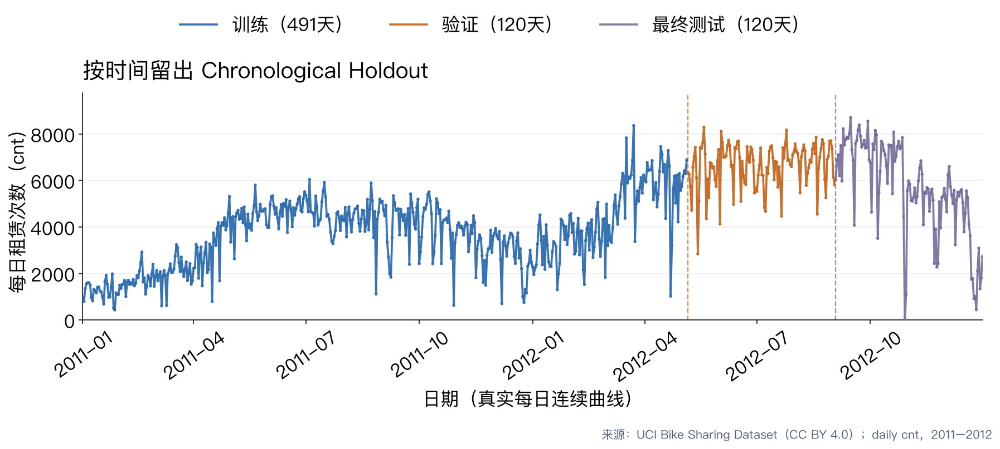

/Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-time-holdout-real.png /Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-time-holdout-real.svg


In [99]:
from time_series_plots import (plot_time_holdout_real, plot_time_windows_real,
                              plot_time_gap_real)

time_holdout_stem = assets_dir / "l6-time-holdout-real"
plot_time_holdout_real(
    bike, holdout_train_idx, holdout_valid_idx, final_test_idx, time_holdout_stem,
)
plt.show()
print(time_holdout_stem.with_suffix(".png"), time_holdout_stem.with_suffix(".svg"))

### expanding 与 rolling：窗口如何向未来前移

<!-- [ref:l6-time-windows] -->

`expanding` 每轮保留全部已到达的历史，规律较稳定、希望积累样本时可考虑；`rolling` 本例每轮只保留最近180天，旧规律可能失效、希望更重视近期数据时可考虑。短窗口也会减少样本量，不能保证更好；应在相同开发验证日期上比较。这里仅展示窗口和真实 `cnt` 曲线，不训练模型。

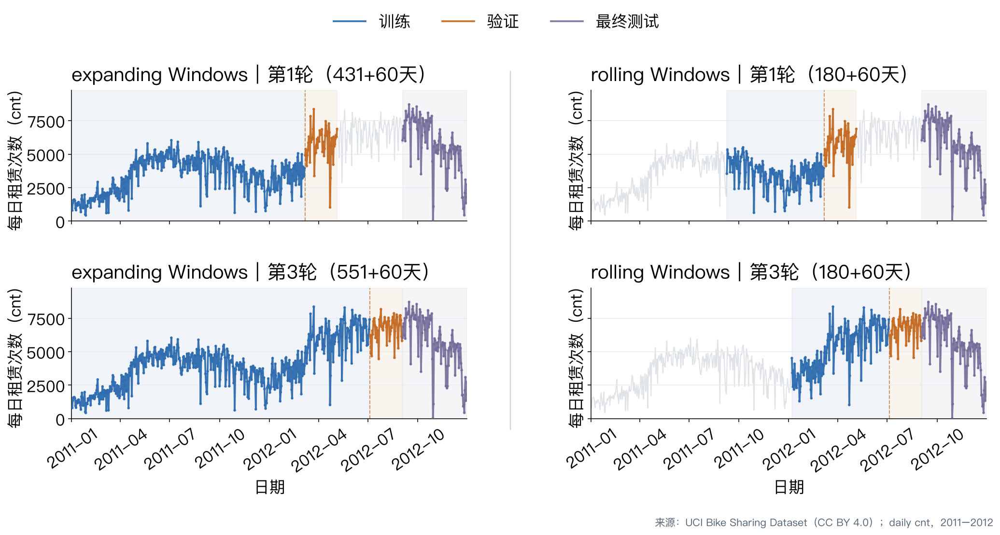

/Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-time-windows-real.png /Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-time-windows-real.svg


In [100]:
time_windows_stem = assets_dir / "l6-time-windows-real"
plot_time_windows_real(
    bike, time_splits_expanding, time_splits_rolling, final_test_idx, time_windows_stem,
)
plt.show()
print(time_windows_stem.with_suffix(".png"), time_windows_stem.with_suffix(".svg"))

### gap 与可得性：留出信息缓冲区

<!-- [ref:l6-time-gap] -->

沿用单车数据，假设新任务是：在记录日当天开始时，仅用此前已知信息预测随后7天的总租赁量。“随后7天”不含当天：5月6日验证记录的目标是5月7日至13日。每天的计数在当天结束后才完整确定。若在2012年5月6日开始验证，4月28日记录的标签覆盖4月29日至5月5日，已完整；4月30日记录的标签覆盖5月1日至5月7日，尚未完整。因而训练暂不使用4月29日至5月5日这7条近期记录，对应图中的 `gap=7`。曲线仍为真实每日 `cnt`，不是七日目标或预测值；本段不训练七日预测器。gap的单位是记录条数，本数据每天一条才等于7天；这里只用 `test_size=60` 指定每折评分块，并不自动实现多步预测。

In [101]:
gap_prediction_start = pd.Timestamp("2012-05-06")
gap_record_days = pd.to_datetime(["2012-04-28", "2012-04-29", "2012-04-30"])
gap_label_end = gap_record_days + pd.Timedelta(days=7)
gap_availability = pd.DataFrame({
    "记录日期": gap_record_days.strftime("%m-%d"),
    "标签起日": (gap_record_days + pd.Timedelta(days=1)).strftime("%m-%d"),
    "标签止日": gap_label_end.strftime("%m-%d"),
    "5月6日开始时已完整": gap_label_end < gap_prediction_start,
})
display(gap_availability)
assert gap_availability.iloc[:, -1].tolist() == [True, False, False]  # 标签须在验证开始前已完整


,记录日期,标签起日,标签止日,5月6日开始时已完整
0,04-28,04-29,05-05,True
1,04-29,04-30,05-06,False
2,04-30,05-01,05-07,False


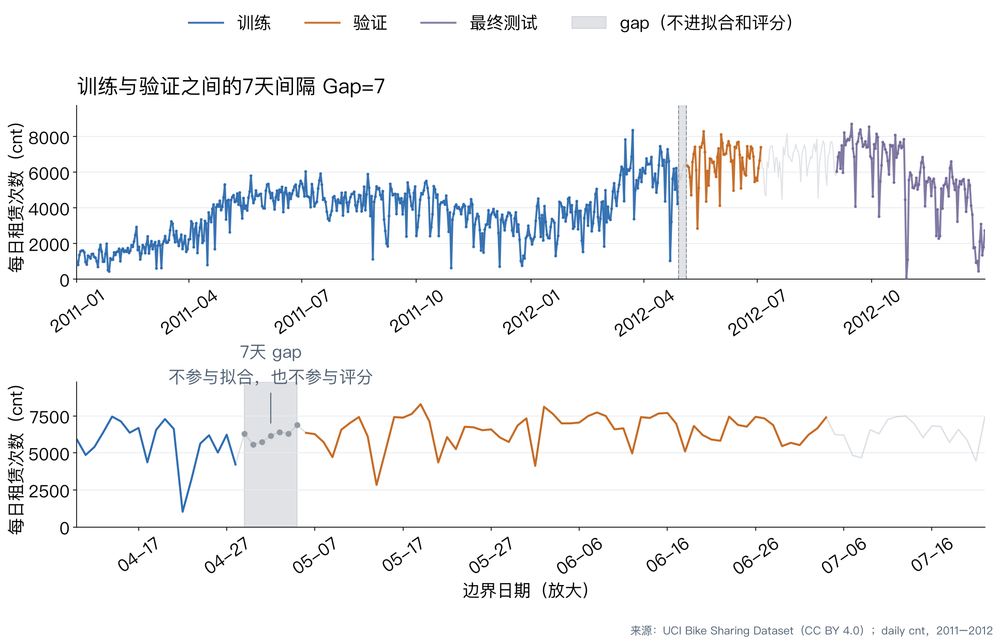

/Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-time-gap-real.png /Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-time-gap-real.svg


In [102]:
gap_train_idx, gap_valid_idx = time_splits_gap[1]
gap_train_idx = development_idx[gap_train_idx]
gap_valid_idx = development_idx[gap_valid_idx]
gap_idx = np.arange(gap_train_idx[-1] + 1, gap_valid_idx[0])
assert len(gap_idx) == 7 and not np.intersect1d(gap_idx, gap_train_idx).size
time_gap_stem = assets_dir / "l6-time-gap-real"
plot_time_gap_real(
    bike, gap_train_idx, gap_idx, gap_valid_idx, final_test_idx, time_gap_stem,
)
plt.show()
print(time_gap_stem.with_suffix(".png"), time_gap_stem.with_suffix(".svg"))

时间、组和随机打乱回答的是不同问题：未来的一周、一个全新的组、还是同分布的新记录。划分协议要先对应部署对象，再比较分数。

## 复盘：怎样判断改进是否值得保留？

1. **先明确评价对象**：留出与CV估计的是特定数据和训练协议下的表现；分组、时间划分要对应新对象或未来记录，不能只挑分数高的协议。
2. **用证据诊断**：学习曲线看训练量，复杂度实验看表达能力与波动，错误分析同时看修正旧错和新增错误。Bootstrap不创造新信息，真实任务通常也没有已知真函数供偏差分解。
3. **有控制地改进**：正则化改变解的偏好，增强改变训练输入，重采样改变训练比例。每次保持评价条件可比，并在每折训练侧学习预处理与采样规则。
4. **选择后再评价**：C与增强强度可用网格／随机搜索比较；早停也使用验证信息。最高CV分数参与了选择，不是独立测试成绩。稀疏、更多训练行或更高训练分数都不自动保证泛化更好。

以下附录保留统计基础与机制图，供自主学习；不要求逐段讲授。

## 可选附录｜Bootstrap均值：统计学基础示例

主线已展示训练集重抽与模型波动；这里用一个不训练模型的基础例子说明通用统计原理：如果重新取得一批样本，算出的均值会波动多大？只有现有样本时，可以把它形成的**经验分布（empirical distribution）**当作总体分布的近似，再有放回地抽取同样多条记录。

代码组织参考[ISLP第5章官方实验](https://islp.readthedocs.io/en/latest/labs/Ch05-resample-lab.html)：先重抽一份，再重复B次，最后计算统计量的标准差。教材的投资组合系数例子改成Iris真实测量值的均值，避免增加金融优化前置知识。

**假设与边界**：下面按独立同分布的抽样框架演示。Iris每个品种各50条，并不证明代表所有鸢尾花；结果只是对这150条数据形成的经验分布进行重抽样。若目标要求固定品种比例，应另行采用分层重抽。这里不对五个CV分数做Bootstrap，也不检验前面五折与LOO差异是否显著。

In [103]:
# [ref:l6-bootstrap-mean-data]
from sklearn.datasets import load_iris

bootstrap_iris = load_iris()
bootstrap_values = bootstrap_iris.data[:, 0]  # 萼片长度，单位cm
bootstrap_n = len(bootstrap_values)
print("真实记录数：", bootstrap_n)
display(pd.DataFrame({"前5条萼片长度（cm）": bootstrap_values[:5]}))


真实记录数： 150


,前5条萼片长度（cm）
0,5.1
1,4.9
2,4.7
3,4.6
4,5.0


### 先看一份重抽样数据

只取前5条真实记录展示抽样步骤，并标为A—E。以下索引有意选来展示重复与遗漏，不是随机运行的前三次结果；后面的标准误差实验使用全部150条。

每次抽取后放回，A可以再次抽到。每份仍有5条，但不保证有5个不同的样本。

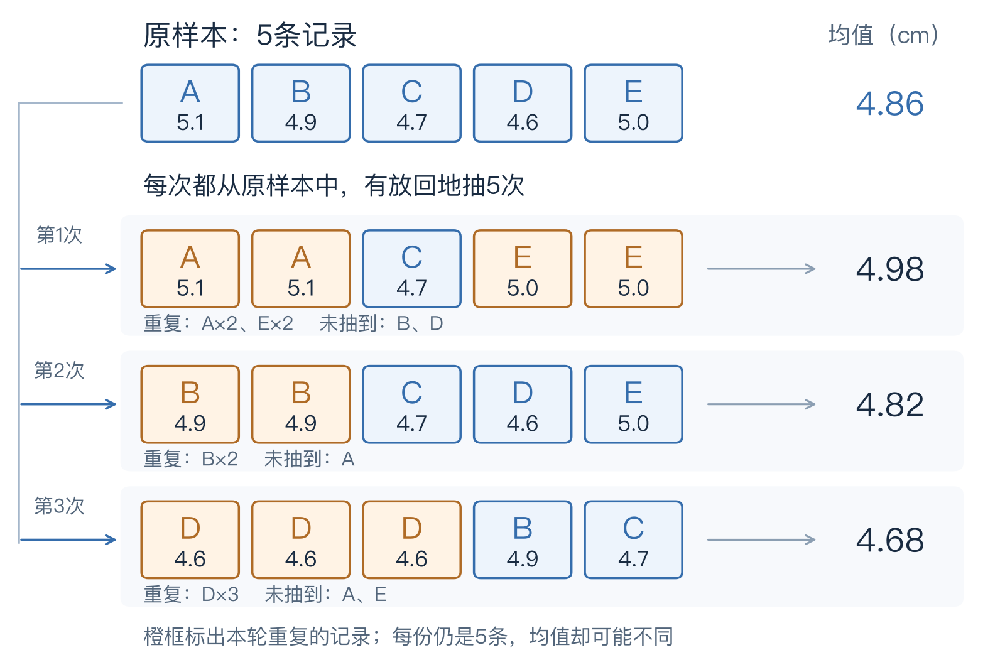

原均值： 4.859999999999999
三份重抽样均值： [4.98 4.82 4.68]


In [104]:
# [ref:l6-bootstrap-mean-draws]
from bootstrap_plots import plot_bootstrap_draws

bootstrap_demo = bootstrap_values[:5]
bootstrap_demo_indices = np.array([
    [0, 0, 2, 4, 4], [1, 1, 2, 3, 4], [3, 3, 3, 1, 2],
])
plot_bootstrap_draws(bootstrap_demo, bootstrap_demo_indices, assets_dir)
plt.show()
print("原均值：", bootstrap_demo.mean())
print("三份重抽样均值：", bootstrap_demo[bootstrap_demo_indices].mean(axis=1))


### 重复2000次，每次都重新计算均值

正式实验从150条记录中有放回抽150条。每一份数据算出一个均值，最终保留2000个均值，而不是把所有重抽样数据拼成更多独立观测。

In [105]:
# [ref:l6-bootstrap-mean-repeat]
bootstrap_B = 2000
bootstrap_rng = np.random.default_rng(SEED)
bootstrap_means = np.empty(bootstrap_B)
for b in range(bootstrap_B):
    bootstrap_sample = bootstrap_rng.choice(
        bootstrap_values, size=bootstrap_n, replace=True,
    )
    bootstrap_means[b] = bootstrap_sample.mean()
print("前5次重抽样均值：", np.round(bootstrap_means[:5], 4))


前5次重抽样均值： [5.9227 5.8533 5.774  5.808  5.9347]


### 标准误差不等于数据本身的标准差

记原始估计为$\hat{\theta}$，本例为样本均值；第$b$份重抽样的结果为$\hat{\theta}^{*(b)}$。Bootstrap标准误差是这$B$个结果的样本标准差：

$$\widehat{\mathrm{SE}}_{\mathrm{boot}}(\hat{\theta})
=\sqrt{\frac{1}{B-1}\sum_{b=1}^{B}
(\hat{\theta}^{*(b)}-\overline{\hat{\theta}^{*}})^2}.$$

这里不再除以$\sqrt{B}$。增加B主要减少计算模拟的随机误差，不能替代增加真实样本量。对于均值，可用$s/\sqrt{n}$作数值核对；不能据此把其他统计量也一律套上这个公式。

In [106]:
# [ref:l6-bootstrap-mean-stats]
bootstrap_se = bootstrap_means.std(ddof=1)
bootstrap_mean_se_reference = bootstrap_values.std(ddof=1) / np.sqrt(bootstrap_n)
bootstrap_mean_summary = {
    "n": bootstrap_n, "B": bootstrap_B, "seed": SEED,
    "mean_cm": float(bootstrap_values.mean()),
    "data_sd_cm": float(bootstrap_values.std(ddof=1)),
    "bootstrap_se_cm": float(bootstrap_se),
    "mean_se_reference_cm": float(bootstrap_mean_se_reference),
}
assert abs(bootstrap_se / bootstrap_mean_se_reference - 1) < 0.1
display(pd.Series(bootstrap_mean_summary).round(4))


n                        150.0000
B                       2000.0000
seed                      42.0000
mean_cm                    5.8433
data_sd_cm                 0.8281
bootstrap_se_cm            0.0668
mean_se_reference_cm       0.0676
dtype: float64

### 对照原始数据与重抽样均值的分布

上图展示花与花之间的测量差异；下图展示每份重抽样均值的波动。两图横轴都是cm，但范围不同。下图虚线是原样本均值，不是已知总体真均值。

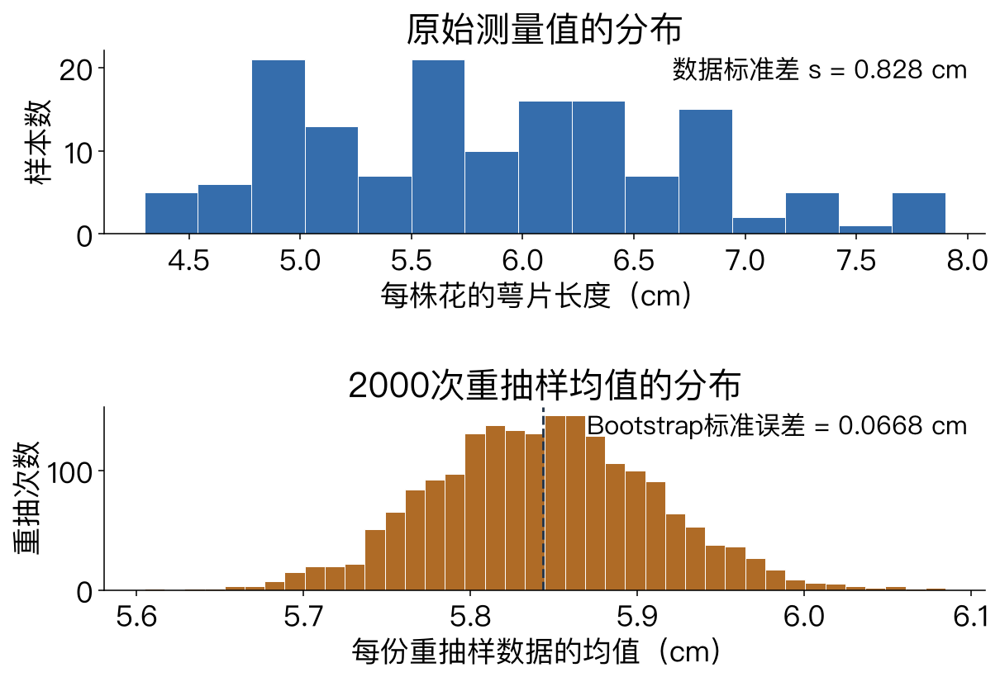

In [107]:
# [ref:l6-bootstrap-mean-distribution]
from bootstrap_plots import plot_bootstrap_distribution, render_bootstrap_formulas

plot_bootstrap_distribution(bootstrap_values, bootstrap_means, assets_dir)
plt.show()
render_bootstrap_formulas(assets_dir)


### 袋外样本：给第7讲随机森林作准备

例如抽出A、A、C、E、E，本次没抽到的B和D就是**袋外样本（out-of-bag, OOB）**。若用袋内样本拟合一个模型，可用本轮袋外样本辅助评价它。下图是流程示意，没有新增模型训练成绩。

对任意一条原始记录，一次抽样不选中它的概率为$1-1/n$，连续n次都没抽到的概率为$(1-1/n)^n$。这也是袋外比例的期望；n较大时趋近$e^{-1}\approx36.8\%$。n=5时精确值为32.768%，与图中一次抽样恰好2/5袋外不同。

本课中，CV主要用于评价泛化和选择方案，Bootstrap在此用于估计统计量的波动，后面还用于训练不同的树。两者并非互斥，也不能把袋内拟合分数当成独立测试分数。

n=5时袋外比例期望： 0.3276800000000001


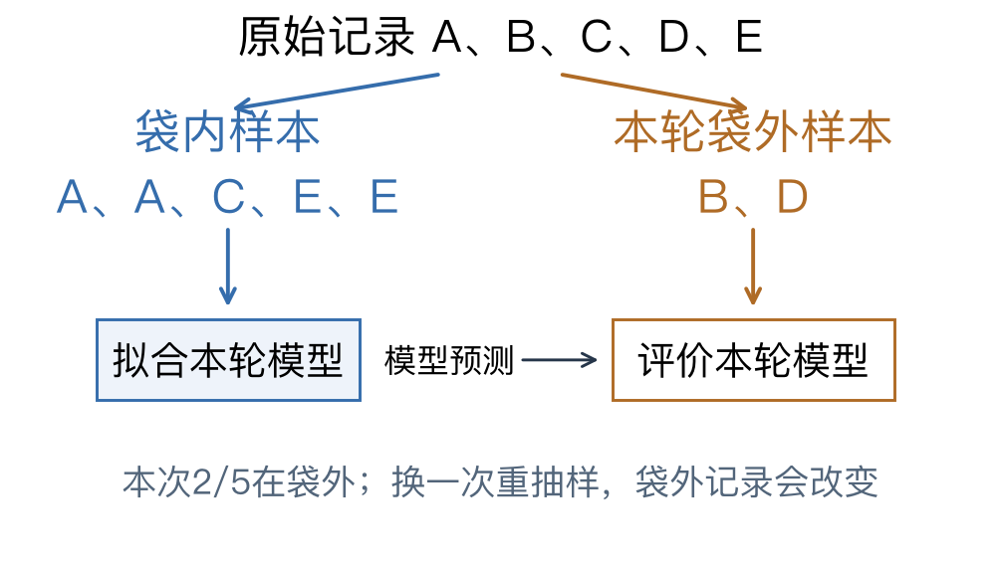

In [108]:
# [ref:l6-bootstrap-mean-oob]
from bootstrap_plots import plot_bootstrap_oob

bootstrap_mean_summary["oob_expected_n5"] = float((1 - 1 / 5) ** 5)
bootstrap_mean_summary["oob_large_n_limit"] = float(np.exp(-1))
print("n=5时袋外比例期望：", bootstrap_mean_summary["oob_expected_n5"])
plot_bootstrap_oob(assets_dir)
plt.show()


**用途与限制**：Bootstrap可帮助估计均值、回归系数等统计量的标准误差，适当方法下还可构造近似置信区间。本节不展开区间方法，也不把它当成无需假设的保证。对同一用户的重复记录应考虑按组重抽，对时序数据应考虑分块方法；逐条打散重抽会破坏原有依赖。Bootstrap不能修复有偏的样本来源。

**参考资料**：[Hastie课程，第27—34页](https://web.stanford.edu/~hastie/MOOC-Slides/cv_boot.pdf)、[Stanford STATS200 Lecture19](https://web.stanford.edu/class/stats200/Lecture19.pdf)、[ISLP Python实验](https://islp.readthedocs.io/en/latest/labs/Ch05-resample-lab.html)。图按抽样原理自行重绘，未复制教材版式或原图。

## 可选扩展｜四种超参数搜索机制

课件用一张四格图概括基本思路；本附录保留四种方法的详细机制图与说明，供自主阅读。以下均为概念插图与教学数值，不是digits上的四方法实测比较。前面的网格/随机搜索结果保持原样。


### 贝叶斯优化怎样选择下一组

**先预测再实测**：已有配置和CV成绩用于建立代理模型，未测配置的预测与不确定性共同参与下一候选选择。采集函数不等于只选最大预测均值或最大不确定性。最终仍需真实训练与验证。

<a href="https://scikit-optimize.readthedocs.io/en/stable/auto_examples/bayesian-optimization.html" target="_blank" rel="noopener">官方图解教程</a> · <a href="https://proceedings.neurips.cc/paper_files/paper/2012/hash/05311655a15b75fab86956663e1819cd-Abstract.html" target="_blank" rel="noopener">Snoek等，2012</a>。


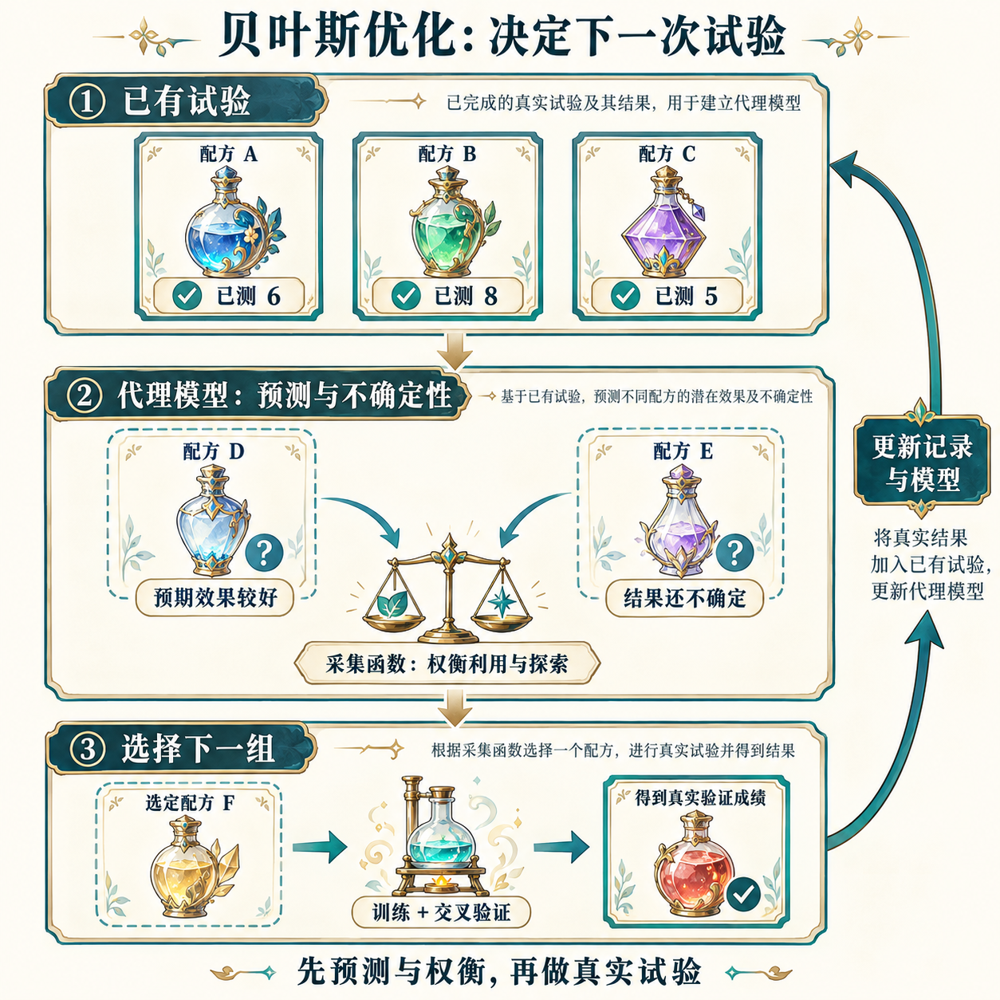

In [109]:
# [ref:l6-search-mechanism-bayes]
from IPython.display import Image, display

# 读取机制示意图；本格不训练模型，也不产生比较成绩。
display(Image(filename=str(assets_dir / "l6-hpo-bayes-mechanism.png")))


### 遗传算法怎样产生新组合

**以GA为例**：个体是超参数组合。交叉交换配置字段，变异改变某些字段；所有新子代都要重新训练与验证。A=(1:2,低)、B=(3:2,中)，交叉后E=(1:2,中)、F=(3:2,低)，本例把E再变异为(2:2,中)。这不是交叉神经网络权重，也不代表DE的具体操作。

<a href="https://sklearngeneticopt.rodrigo-arenas.com/versions/0.13/api/gasearchcv.html" target="_blank" rel="noopener">GASearchCV文档</a> · <a href="https://deap.readthedocs.io/en/master/api/algo.html" target="_blank" rel="noopener">DEAP算法流程</a>。


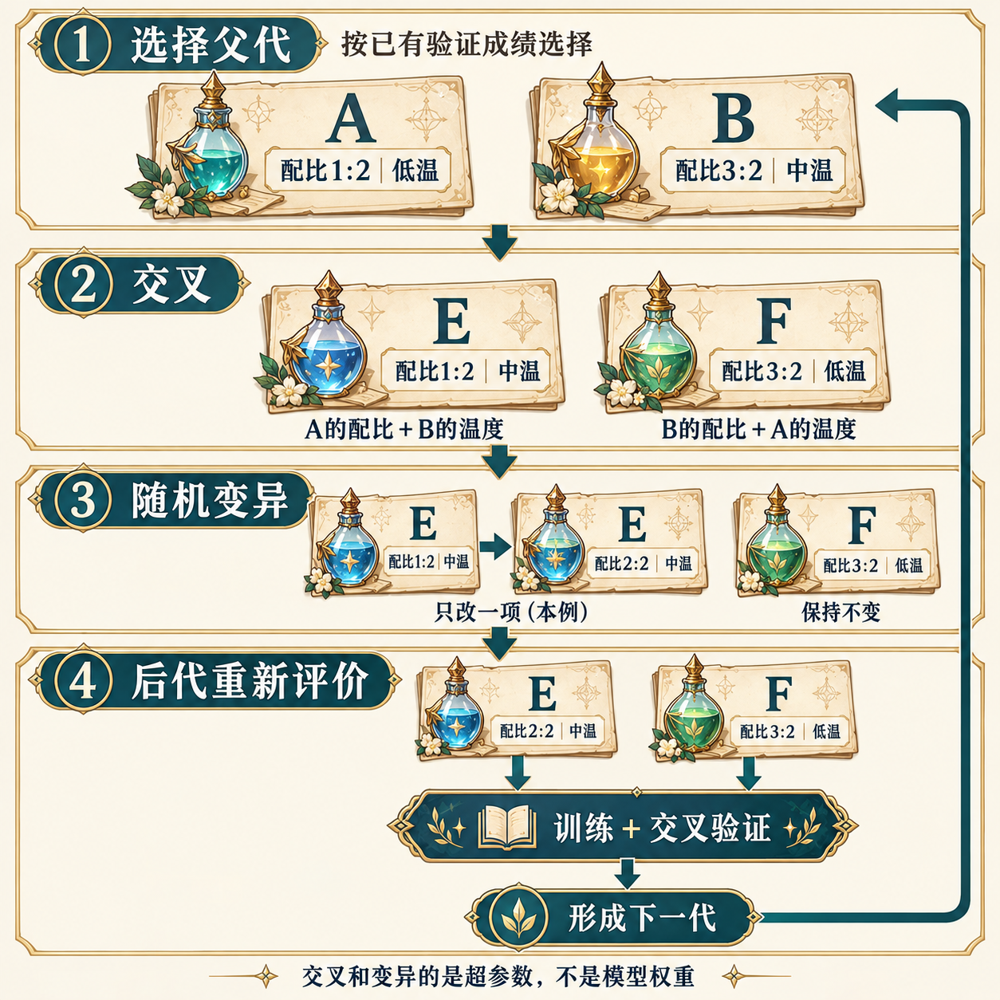

In [110]:
# [ref:l6-search-mechanism-evolution]
from IPython.display import Image, display

# 读取机制示意图；本格不训练模型，也不产生比较成绩。
display(Image(filename=str(assets_dir / "l6-hpo-evolution-mechanism.png")))


### 模拟退火为何接受较差方案

**经典模拟退火示意**：最小化验证损失，$\Delta=L_{new}-L_{current}$。$\Delta>0$时接受概率为$\exp(-\Delta/T)$。图中$\Delta=0.05$，$T=0.10$时约60.65%，$T=0.01$时约0.674%。这是算法搜索温度，与配方里的加热温度不同；当前候选与历史最佳要分别保留。SciPy的dual_annealing是相关变体，不是逐字实现这段简化规则。

<a href="https://www2.stat.duke.edu/~scs/Courses/Stat376/Papers/TemperAnneal/KirkpatrickAnnealScience1983.pdf" target="_blank" rel="noopener">经典论文PDF</a> · <a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.dual_annealing.html" target="_blank" rel="noopener">SciPy变体文档</a>。


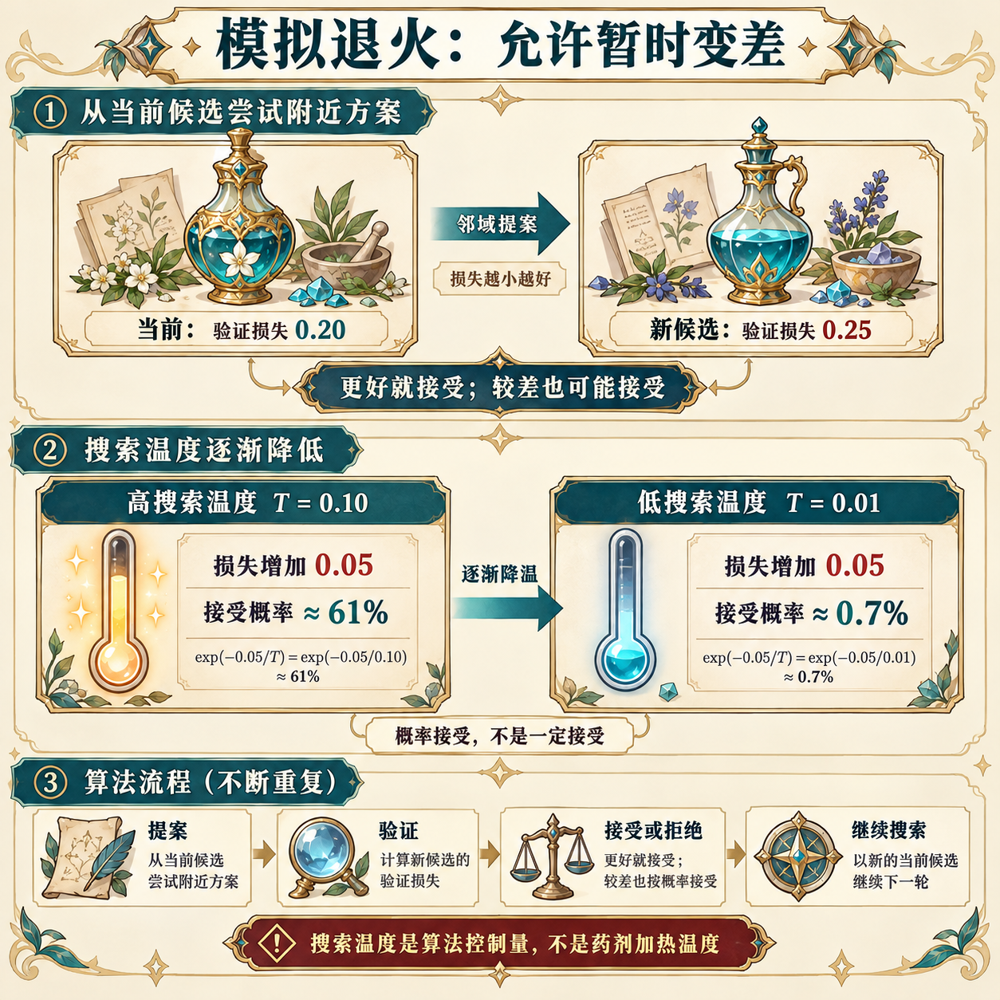

In [111]:
# [ref:l6-search-mechanism-annealing]
from IPython.display import Image, display

# 读取机制示意图；本格不训练模型，也不产生比较成绩。
display(Image(filename=str(assets_dir / "l6-hpo-annealing-mechanism.png")))


### 逐次减半怎样分配资源

**训练资源总量**：图中固定同一份验证集，各候选本轮分别用100、300、900条训练记录，候选数量由9变3变1，参数配置不变。数值是教学设定，不是sklearn每折样本数；若使用Halving*CV，resource="n_samples"须按API的CV及子采样口径理解。小资源下落后不证明充分训练后仍落后。

<a href="https://scikit-learn.org/stable/auto_examples/model_selection/plot_successive_halving_iterations.html" target="_blank" rel="noopener">sklearn逐轮示例</a> · <a href="https://proceedings.mlr.press/v51/jamieson16.html" target="_blank" rel="noopener">Jamieson等，2016</a>。


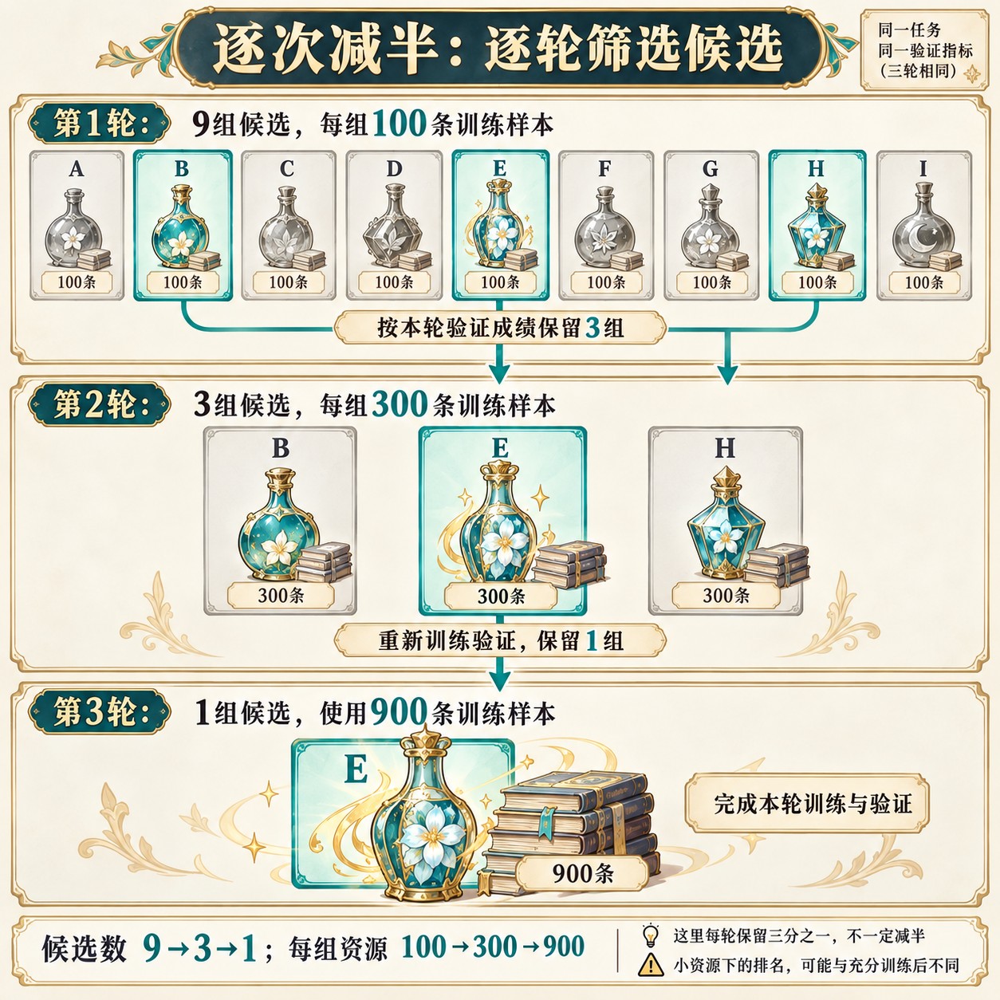

In [112]:
# [ref:l6-search-mechanism-halving]
from IPython.display import Image, display

# 读取机制示意图；本格不训练模型，也不产生比较成绩。
display(Image(filename=str(assets_dir / "l6-hpo-halving-mechanism.png")))


## 维护用导出｜保存本次实验结果

以下单元只从本次执行的变量保存图表证据与JSON汇总，不重新训练，也不读取预留标签。学习曲线、验证曲线等已在对应段落展示。

In [113]:
# 汇总仅来自本次Notebook实际变量；放在所有实验与附录之后。
import json
summary = {
    "lesson": "06-model-selection", "seed": SEED,
    "environment": {"python": sys.version.split()[0], "sklearn": sklearn.__version__},
    "source": {
        "digits": "scikit-learn load_digits",
        "grouping": "INRIA scikit-learn MOOC Sample grouping, CC-BY-4.0",
        "code_license": "scikit-learn BSD-3-Clause; course manifest records upstream revision",
    },
    "digits_sizes": {"total": len(y), "development": len(y_develop),
                     "opening_train": len(y_open_train), "opening_validation": len(y_open_valid),
                     "reserved": len(y_reserved)},
    "candidates": {"opening": CANDIDATES_OPENING, "development_cv": CANDIDATES_CV},
    "opening_fixed_holdout": opening_table.to_dict(orient="records"),
    "development_cv": cv_table_for_plot.to_dict(orient="records"),
    "loo_comparison": protocol_comparison.to_dict(orient="records"),
    "loo_both_wrong": both_wrong,
    "bootstrap": bootstrap_summary,
    "leakage": {"table": leakage_table.to_dict(orient="records"), "pipeline_scores": safe_scores.tolist()},
    "group_protocols": all_scores.to_dict(orient="list"),
    "time_split": time_table.to_dict(orient="records"),
    "complexity_bootstrap": bootstrap_complexity_summary,
    "regularization_effect": regularization_demo,
    "conceptual_extensions": ["Elastic Net", "Early Stopping and Checkpoint", "Few-shot baselines and meta-learning"],
    "complexity_simulation": {
        "true_function": "sin(pi*x)", "grid": [-0.9, 0.9], "noise_std": COMPLEXITY_NOISE_STD,
        "repeats": COMPLEXITY_REPEATS, "n_train": COMPLEXITY_N_TRAIN,
        "rows": complexity_table.to_dict(orient="records"),
        "decomposition_max_abs_error": decomposition_max_error,
    },
    "new_experiments": {
        "anchors": ["l6-validation-curve", "l6-penalty", "l6-search-budget", "l6-search-random", "l6-augmentation", "l6-fewshot", "l6-optimization", "l6-errors", "l6-leakage"],
        "validation_curve_C": validation_curve_table.to_dict(orient="records"),
        "penalty_comparison": penalty_table.to_dict(orient="records"),
        "search_budget": search_budget,
        "search_grid_cv_results": grid_results[search_columns].to_dict(orient="records"),
        "search_random_cv_results": random_results[search_columns].to_dict(orient="records"),
        "augmentation": augmentation_summary,
        "class_resampling": sampling_summary,
        "fewshot_protocol": fewshot_protocol_table.to_dict(orient="records"),
        "optimization": optimization_summary,
        "errors": error_summary,
        "penalty_convergence_warnings": penalty_convergence_warnings,
        "search_warning_counts": {"grid": grid_warning_counts, "random": random_warning_counts},
    },
    "assets": sorted(p.name for p in assets_dir.glob("l6-*.png")),
}
for summary_name in ["l6-revision-summary.json", "l6-generalization-summary.json"]:
    (assets_dir / summary_name).write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("已写入:", assets_dir / "l6-revision-summary.json")
print("已写入:", assets_dir / "l6-generalization-summary.json")

已写入: /Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-revision-summary.json
已写入: /Users/momo/Documents/workspace/教学/2026机器学习与概率统计-本科/lessons/06-model-selection/assets/l6-generalization-summary.json
